# 02 · Exploración de cinco años: clasificación ABC y XYZ global

Flujo: (1) fuentes, (2) métricas por artículo sobre los cinco años, (3) clasificación ABC, (4) cortes XYZ, (5) matriz ABC × XYZ, (6) caracterización de los grupos y diagnóstico de ceros, (7) regla de cortes ABC, (8) análisis interanual, (9) análisis intraanual y estacionalidad. Cada cálculo se hace a la vista y su resultado se muestra en el notebook. No se congela nada.

In [1]:
import os
import sys
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/. PROJECT_ROOT permite apuntar a otra carpeta
# de datos (por ejemplo, una copia sintética para validar el flujo).
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from statsmodels.stats.multitest import multipletests

from src.config import all_years, load_validated_config
from src.data import active_stores_by_item, load_calendar, load_interim
from src.segmentation import (
    build_matrix,
    classical_seasonal_index,
    classify_abc,
    classify_xyz,
    compute_cv,
    compute_usage_spend,
    describe_items,
    drop_zero_runs,
    find_cv_cuts,
    friedman_seasonality,
    seasonal_strength,
    seasonal_strength_items,
    select_abc_cuts,
    zero_breakdown,
    zero_runs,
)
from src.stability import (
    EDA_PSI,
    ABC_LABELS,
    CELL_LABELS,
    SEGMENT_PREFIX,
    XYZ_LABELS,
    base_target_classes,
    interleaved_halves,
    period_matrices,
    period_pairs,
    prior_years_map,
    segment_bounds,
    transition_stats,
    year_matrices,
)

# Si es True, las figuras de las secciones 3 y 6 se guardan en reports/figures/.
SAVE_FIGURES = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
%matplotlib inline

cfg = load_validated_config()
seg = cfg["segmentation"]
print("versión de la config:", cfg["version"])
print("segmentación:", seg)

versión de la config: v1
segmentación: {'usage_period': 'computation_set', 'abc_cuts': [0.8, 0.95], 'xyz_thresholds': [10.0, 25.0], 'cv_aggregation': 'block28', 'cv_min_blocks': 2}


## 1 · Fuentes de datos

Vista previa de los archivos crudos y de los arreglos intermedios que alimentan los cálculos.

In [2]:
raw_dir = Path(cfg["data"]["raw_dir"])
last_day = cfg["data"]["last_day"]

# Calendario: un registro por día (d_1 … d_n) con su semana wm_yr_wk.
calendar = load_calendar(cfg)
print(f"calendar.csv: {calendar.shape[0]} días, de {calendar['date'].min()} a {calendar['date'].max()}")
display(calendar.head())

calendar.csv: 1969 días, de 2011-01-29 a 2016-06-19


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [3]:
# Ventas crudas (solo 5 filas y las primeras columnas de días): una fila por serie tienda-artículo.
sales_head = pd.read_csv(raw_dir / cfg["data"]["sales_file"], nrows=5)
print(f"{cfg['data']['sales_file']}: {sales_head.shape[1]} columnas en la vista previa")
display(sales_head.iloc[:, :12])

# Precios crudos (solo 5 filas): precio de venta por tienda, artículo y semana.
prices_head = pd.read_csv(raw_dir / "sell_prices.csv", nrows=5)
display(prices_head)

sales_train_evaluation.csv: 1947 columnas en la vista previa


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [4]:
# Intermedios por artículo (unidades y gasto = Σ unidades × precio por tienda-día), días 1..last_day.
# NaN = día sin dato (prelanzamiento o enmascarado).
source_data_artifact = load_interim(cfg, last_day)
item_ids = source_data_artifact["item_ids"]
print(f"artículos: {len(item_ids)} · días: {source_data_artifact['item_units'].shape[1]}")

day_cols = [f"d_{d}" for d in range(1, 9)]
display(pd.DataFrame(source_data_artifact["item_units"][:5, :8], index=item_ids[:5], columns=day_cols).rename_axis("unidades"))
display(pd.DataFrame(source_data_artifact["item_spend"][:5, :8], index=item_ids[:5], columns=day_cols).rename_axis("gasto"))
display(pd.DataFrame({"item_id": item_ids, "item_launch_d": source_data_artifact["item_launch_d"]}).head())

artículos: 3049 · días: 1941


,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8
unidades,,,,,,,,
FOODS_1_001,6.00,6.00,4.00,6.00,7.00,18.00,10.00,4.00
FOODS_1_002,4.00,5.00,7.00,4.00,3.00,4.00,1.00,7.00
FOODS_1_003,14.00,8.00,3.00,6.00,3.00,8.00,13.00,10.00
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,34.00,32.00,13.00,20.00,10.00,21.00,18.00,20.00


,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8
gasto,,,,,,,,
FOODS_1_001,12.00,12.00,8.00,12.00,14.00,36.00,20.00,8.00
FOODS_1_002,31.92,39.40,55.16,31.52,23.64,31.92,7.88,55.16
FOODS_1_003,40.32,23.04,8.64,17.28,8.64,23.04,37.44,28.80
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,100.86,94.38,38.52,59.10,29.40,63.24,53.22,59.40


,item_id,item_launch_d
0,FOODS_1_001,1.00
1,FOODS_1_002,1.00
2,FOODS_1_003,1.00
3,FOODS_1_004,400.00
4,FOODS_1_005,1.00


In [5]:
# Ventana de los cinco años (los días anteriores a Y1 son historia previa y no se usan aquí).
years = all_years(cfg)
years_table = pd.DataFrame(years, index=["start_d", "end_d"]).T
years_table["days"] = years_table["end_d"] - years_table["start_d"] + 1
display(years_table)

start_d, end_d = years["Y1"][0], years["Y5"][1]
print(f"ventana global: d_{start_d} a d_{end_d} ({end_d - start_d + 1} días)")

,start_d,end_d,days
Y1,122,485,364
Y2,486,849,364
Y3,850,1213,364
Y4,1214,1577,364
Y5,1578,1941,364


ventana global: d_122 a d_1941 (1820 días)


## 2 · Métricas globales (los cinco años)

- **Uso** y **gasto**: suma de unidades y de Σ unidades × precio en la ventana; un artículo es *activo* si tiene al menos un día con dato.
- **CV**: desviación estándar poblacional / media × 100 sobre bloques completos de 28 días (`cv_aggregation = block28`); es indefinido con menos de `cv_min_blocks` bloques o media 0.
- **Descripción diaria**: media, mediana y proporción de ceros sobre días activos.

In [6]:
# Uso y gasto por artículo.
usage_spend = compute_usage_spend(source_data_artifact["item_units"], source_data_artifact["item_spend"], start_d, end_d)
usage_spend.insert(0, "item_id", item_ids)
display(usage_spend.head().style.set_caption("Df Usages-Spend"))

# CV por artículo.
cv_df = compute_cv(
    source_data_artifact["item_units"], start_d, end_d, seg["cv_aggregation"], seg["cv_min_blocks"], source_data_artifact["week_of_day"]
)
display(cv_df.head().style.set_caption("DF CV RAW"))

# Media, mediana y proporción de ceros por día.
daily = describe_items(source_data_artifact, start_d, end_d)
display(daily.head().style.set_caption("DF Daily"))

,item_id,usage,spend,active
0,FOODS_1_001,11145.000000,24087.180152,True
1,FOODS_1_002,7008.000000,63094.619352,True
2,FOODS_1_003,12445.000000,36732.641209,True
3,FOODS_1_004,132251.000000,241427.220337,True
4,FOODS_1_005,21098.000000,71388.139514,True


,cv,n_blocks
0,42.493648,65
1,12.952393,65
2,25.716377,65
3,43.635525,55
4,65.063809,65


,item_id,active_days,zero_share,mean_daily_units,median_daily_units,total_units
0,FOODS_1_001,1820,0.103297,6.123626,5.000000,11145.000000
1,FOODS_1_002,1820,0.041758,3.850549,4.000000,7008.000000
2,FOODS_1_003,1820,0.017033,6.837912,6.000000,12445.000000
3,FOODS_1_004,1542,0.096628,85.765888,84.000000,132251.000000
4,FOODS_1_005,1820,0.239560,11.592308,11.000000,21098.000000


In [7]:
# Una sola tabla de métricas por artículo.
metrics = (
    usage_spend.rename(columns={"usage": "usage_units"})
    .join(cv_df)
    .merge(daily.drop(columns="total_units"), on="item_id")
)
display(metrics.head())

# Resumen global: lo que se agrega y lo que queda sin cálculo.
active = metrics[metrics["active"]]
summary = pd.Series(
    {
        "artículos": len(metrics),
        "activos en la ventana": len(active),
        "inactivos": int((~metrics["active"]).sum()),
        "activos con CV indefinido": int(active["cv"].isna().sum()),
        "unidades totales": metrics["usage_units"].sum(),
        "gasto total": metrics["spend"].sum(),
        "CV mediano (%)": active["cv"].median(),
    },
    name="valor",
)
display(summary.to_frame())
display(metrics[["usage_units", "spend", "cv", "n_blocks", "mean_daily_units", "median_daily_units", "zero_share"]].describe())

,item_id,usage_units,spend,active,cv,n_blocks,active_days,zero_share,mean_daily_units,median_daily_units
0,FOODS_1_001,"11,145.00","24,087.18",True,42.49,65,1820,0.10,6.12,5.00
1,FOODS_1_002,"7,008.00","63,094.62",True,12.95,65,1820,0.04,3.85,4.00
2,FOODS_1_003,"12,445.00","36,732.64",True,25.72,65,1820,0.02,6.84,6.00
3,FOODS_1_004,"132,251.00","241,427.22",True,43.64,55,1542,0.10,85.77,84.00
4,FOODS_1_005,"21,098.00","71,388.14",True,65.06,65,1820,0.24,11.59,11.00


,valor
artículos,"3,049.00"
activos en la ventana,"3,049.00"
inactivos,0.00
activos con CV indefinido,0.00
unidades totales,"63,933,886.00"
gasto total,"183,470,201.68"
CV mediano (%),37.16


,usage_units,spend,cv,n_blocks,mean_daily_units,median_daily_units,zero_share
count,"3,049.00","3,049.00","3,049.00","3,049.00","3,049.00","3,049.00","3,049.00"
mean,"20,968.80","60,173.89",41.80,54.80,13.03,12.11,0.15
std,"42,891.36","91,194.62",22.02,14.20,24.46,23.79,0.14
min,593.00,457.93,8.49,14.00,0.35,0.00,0.00
25%,"4,320.00","17,731.57",25.61,45.00,3.22,3.00,0.03
50%,"9,369.00","34,252.08",37.16,65.00,6.26,6.00,0.10
75%,"20,748.00","65,949.90",53.91,65.00,13.03,12.00,0.22
max,"1,008,855.00","1,444,850.11",192.52,65.00,554.32,556.00,0.78


## 3 · Matriz de clasificación por artículo

- **ABC**: se ordena por gasto descendente y se mira el % acumulado *antes* de sumar el artículo; es A si es menor que el primer corte, B si es menor que el segundo y C en otro caso.
- **XYZ**: X si CV < umbral X, Y si CV < umbral Z y Z en otro caso.

In [8]:
# ABC: solo artículos activos, ordenados por gasto (empates por item_id).
abc = classify_abc(active["item_id"], active["spend"].to_numpy(), seg["abc_cuts"])
display(abc.head())
display(abc.groupby("abc_class").agg(items=("item_id", "size"), spend=("spend", "sum")).assign(
    spend_pct=lambda t: t["spend"] / t["spend"].sum() * 100))

,item_id,spend,cum_spend,cum_pct_before,abc_class
0,FOODS_3_120,"1,444,850.11","1,444,850.11",0.00,A
1,FOODS_3_586,"1,395,728.81","2,840,578.91",0.01,A
2,FOODS_3_090,"1,366,337.80","4,206,916.71",0.02,A
3,FOODS_3_202,"1,212,799.69","5,419,716.40",0.02,A
4,FOODS_3_587,"893,838.15","6,313,554.55",0.03,A


,items,spend,spend_pct
abc_class,,,
A,1274,"146,803,540.23",80.01
B,928,"27,506,032.44",14.99
C,847,"9,160,629.00",4.99


### 3.1 · Pareto con doble eje y sensibilidad de los cortes ABC

Barras: gasto anual promedio por artículo (gasto de los cinco años / 5), en el eje principal. Línea: gasto acumulado porcentual, en el eje secundario. Las barras se colorean con los cortes configurados.

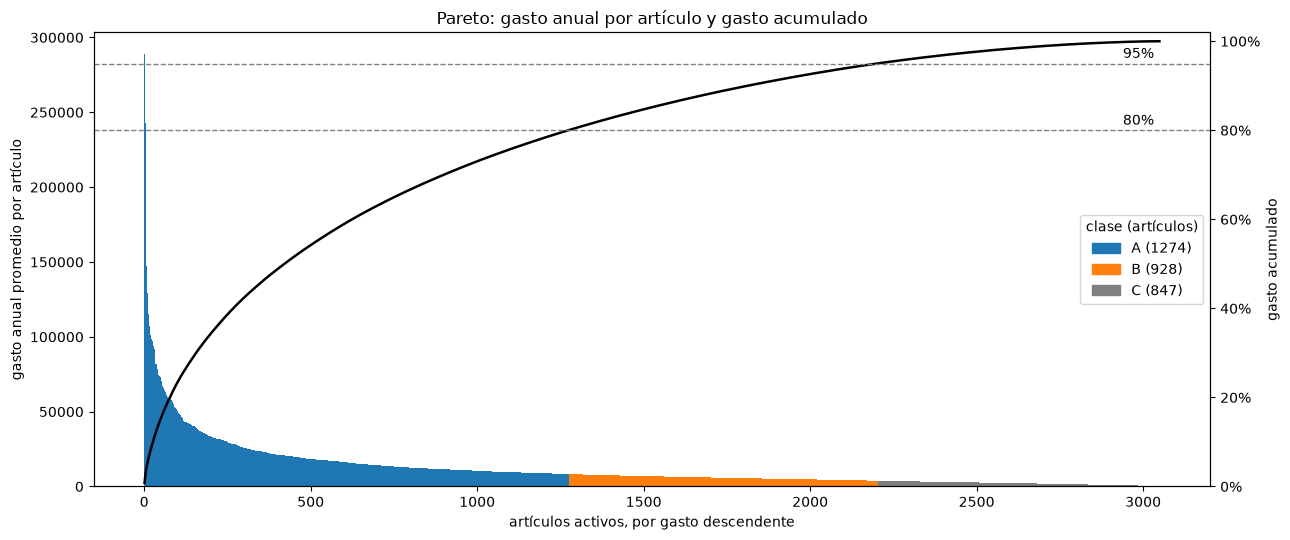

In [9]:
n_years = len(years)
colors = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#7f7f7f"}
# abc ya trae solo los artículos activos, ordenados por gasto, con cum_spend y abc_class.
ranked = abc.copy()
rank = np.arange(1, len(ranked) + 1)
annual_spend = ranked["spend"] / n_years
cum_pct = ranked["cum_spend"] / ranked["spend"].sum()

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(rank, annual_spend, width=1.0, color=ranked["abc_class"].map(colors), linewidth=0)
ax.set(title="Pareto: gasto anual por artículo y gasto acumulado", xlabel="artículos activos, por gasto descendente",
       ylabel="gasto anual promedio por artículo")
ax.margins(x=0)

ax2 = ax.twinx()
ax2.plot(rank, cum_pct, color="black", linewidth=1.8)
for cut in seg["abc_cuts"]:
    ax2.axhline(cut, color="grey", linestyle="--", linewidth=1)
    ax2.annotate(f"{cut:.0%}", (rank[-1], cut), xytext=(-4, 4), textcoords="offset points", ha="right")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set(ylabel="gasto acumulado", ylim=(0, 1.02))

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, [f"{k} ({(ranked['abc_class'] == k).sum()})" for k in colors], title="clase (artículos)", loc="center right")
fig.tight_layout()
if SAVE_FIGURES:
    out = Path("reports/figures")
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "eda_five_years_pareto.png", dpi=150, bbox_inches="tight")
    print("figura guardada en", out / "eda_five_years_pareto.png")
plt.show()

### 3.2 · Escenarios de corte

Se repite `classify_abc` con distintos cortes de gasto acumulado (A, B). Por cada escenario: recuento de artículos, % de los artículos (unidades de inventario, SKU) y % del gasto de cada clase.

In [10]:
a_cuts = [0.50, 0.60, 0.70, 0.80, 0.90]
b_cuts = [0.90, 0.95, 0.98]
total_items = len(ranked)

rows = []
for a in a_cuts:
    for b in b_cuts:
        if a >= b:
            continue
        r = classify_abc(ranked["item_id"], ranked["spend"].to_numpy(), [a, b])
        by = r.groupby("abc_class").agg(items=("item_id", "size"), spend=("spend", "sum"))
        by = by.reindex(["A", "B", "C"], fill_value=0)
        row = {"corte_A": a, "corte_B": b}
        for cls in ("A", "B", "C"):
            row[f"{cls}_items"] = int(by.loc[cls, "items"])
            row[f"{cls}_%items"] = by.loc[cls, "items"] / total_items * 100
            row[f"{cls}_%gasto"] = by.loc[cls, "spend"] / by["spend"].sum() * 100
        rows.append(row)
scenarios = pd.DataFrame(rows)
scenarios["escenario"] = [f"A≤{a:.0%} · B≤{b:.0%}" for a, b in zip(scenarios["corte_A"], scenarios["corte_B"])]
assert (scenarios[["A_items", "B_items", "C_items"]].sum(axis=1) == total_items).all()
display(scenarios.set_index("escenario").round(2))

,corte_A,corte_B,A_items,A_%items,A_%gasto,B_items,B_%items,B_%gasto,C_items,C_%items,C_%gasto
escenario,,,,,,,,,,,
A≤50% · B≤90%,0.50,0.90,421,13.81,50.01,1391,45.62,39.99,1237,40.57,10.00
A≤50% · B≤95%,0.50,0.95,421,13.81,50.01,1781,58.41,45.00,847,27.78,4.99
A≤50% · B≤98%,0.50,0.98,421,13.81,50.01,2127,69.76,47.99,501,16.43,2.00
A≤60% · B≤90%,0.60,0.90,625,20.50,60.04,1187,38.93,29.96,1237,40.57,10.00
A≤60% · B≤95%,0.60,0.95,625,20.50,60.04,1577,51.72,34.97,847,27.78,4.99
A≤60% · B≤98%,0.60,0.98,625,20.50,60.04,1923,63.07,37.96,501,16.43,2.00
A≤70% · B≤90%,0.70,0.90,900,29.52,70.03,912,29.91,19.98,1237,40.57,10.00
A≤70% · B≤95%,0.70,0.95,900,29.52,70.03,1302,42.70,24.98,847,27.78,4.99
A≤70% · B≤98%,0.70,0.98,900,29.52,70.03,1648,54.05,27.97,501,16.43,2.00


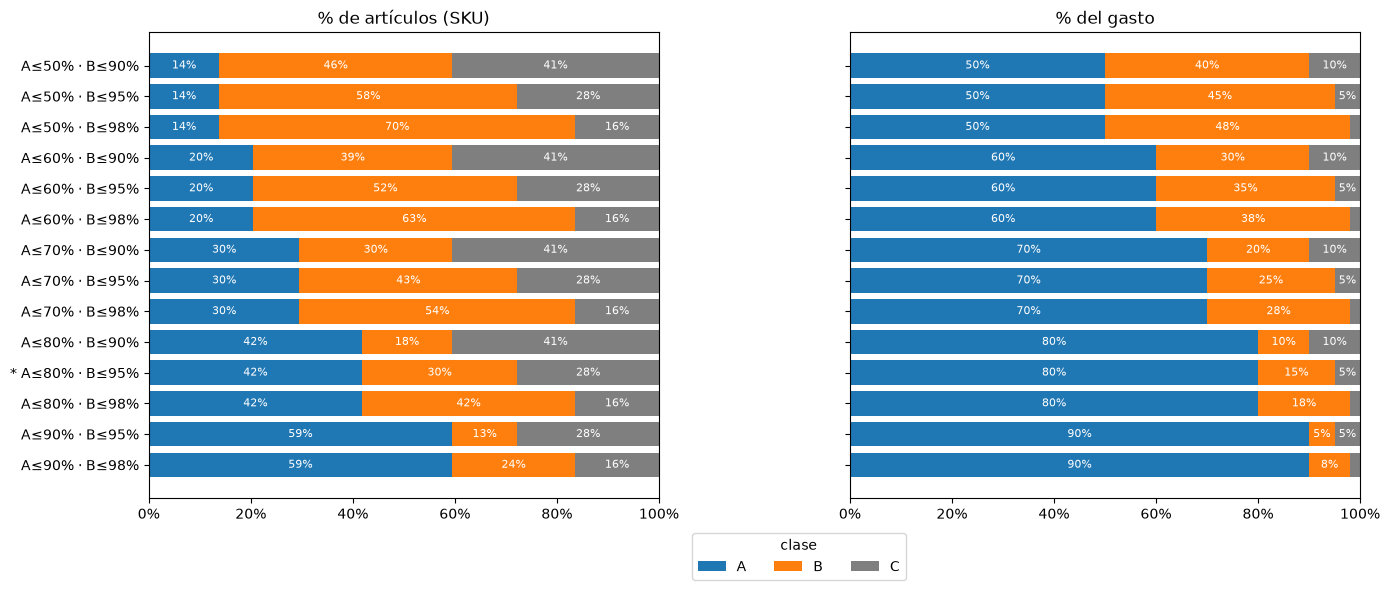

In [11]:
# Reparto de artículos y de gasto por escenario (el escenario configurado va marcado con *).
labels = [("* " if [a, b] == list(seg["abc_cuts"]) else "") + e
          for a, b, e in zip(scenarios["corte_A"], scenarios["corte_B"], scenarios["escenario"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, kind, title in zip(axes, ("%items", "%gasto"), ("% de artículos (SKU)", "% del gasto")):
    left = np.zeros(len(scenarios))
    for cls, color in colors.items():
        vals = scenarios[f"{cls}_{kind}"].to_numpy()
        ax.barh(labels, vals, left=left, color=color, label=cls)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v >= 4:
                ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
        left += vals
    ax.set(title=title, xlim=(0, 100))
    ax.xaxis.set_major_formatter(PercentFormatter(100))
axes[0].invert_yaxis()
axes[1].legend(title="clase", loc="upper center", bbox_to_anchor=(-0.1, -0.06), ncol=3)
fig.tight_layout()
plt.show()

In [12]:
# Cortes seleccionados mediante itertacion
CUT_A = 0.6
CUT_B = 0.9

# ABC: solo artículos activos, ordenados por gasto (empates por item_id).
abc = classify_abc(active["item_id"], active["spend"].to_numpy(), [CUT_A, CUT_B])
display(abc.head())
display(abc.groupby("abc_class").agg(items=("item_id", "size"), spend=("spend", "sum")).assign(
    spend_pct=lambda t: t["spend"] / t["spend"].sum() * 100))

,item_id,spend,cum_spend,cum_pct_before,abc_class
0,FOODS_3_120,"1,444,850.11","1,444,850.11",0.00,A
1,FOODS_3_586,"1,395,728.81","2,840,578.91",0.01,A
2,FOODS_3_090,"1,366,337.80","4,206,916.71",0.02,A
3,FOODS_3_202,"1,212,799.69","5,419,716.40",0.02,A
4,FOODS_3_587,"893,838.15","6,313,554.55",0.03,A


,items,spend,spend_pct
abc_class,,,
A,625,"110,154,355.39",60.04
B,1187,"54,975,936.54",29.96
C,1237,"18,339,909.75",10.00


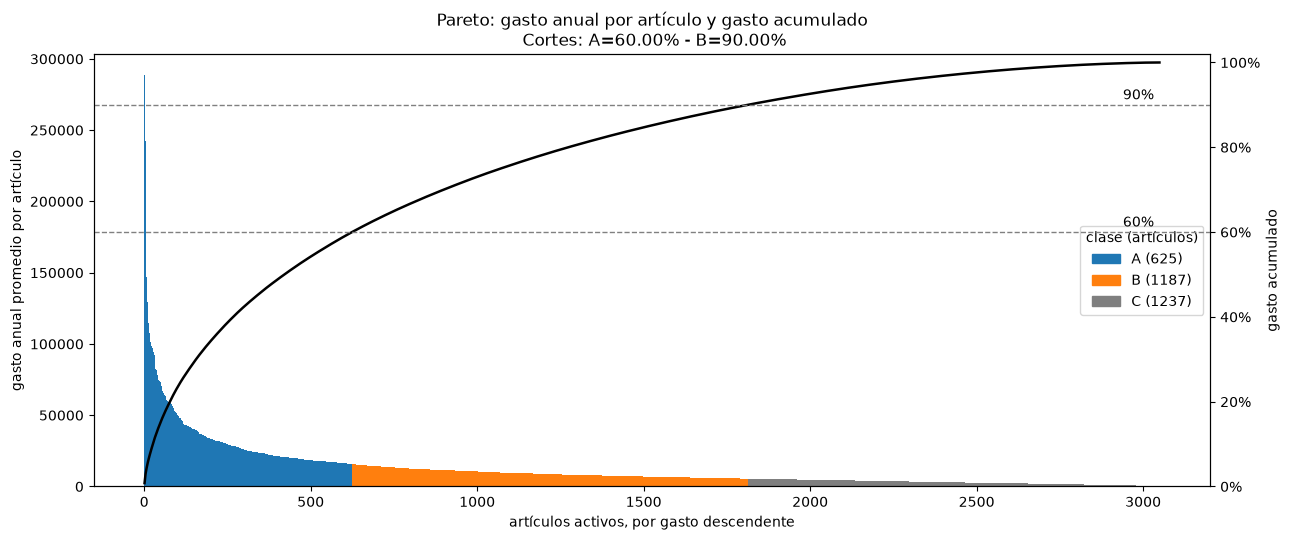

In [13]:
n_years = len(years)
colors = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#7f7f7f"}
# abc ya trae solo los artículos activos, ordenados por gasto, con cum_spend y abc_class.
ranked = abc.copy()
rank = np.arange(1, len(ranked) + 1)
annual_spend = ranked["spend"] / n_years
cum_pct = ranked["cum_spend"] / ranked["spend"].sum()

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(rank, annual_spend, width=1.0, color=ranked["abc_class"].map(colors), linewidth=0)
ax.set(title=f"Pareto: gasto anual por artículo y gasto acumulado\n Cortes: A={CUT_A:.2%} - B={CUT_B:.2%}", xlabel="artículos activos, por gasto descendente",
       ylabel="gasto anual promedio por artículo")
ax.margins(x=0)

ax2 = ax.twinx()
ax2.plot(rank, cum_pct, color="black", linewidth=1.8)
for cut in [CUT_A, CUT_B]:
    ax2.axhline(cut, color="grey", linestyle="--", linewidth=1)
    ax2.annotate(f"{cut:.0%}", (rank[-1], cut), xytext=(-4, 4), textcoords="offset points", ha="right")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set(ylabel="gasto acumulado", ylim=(0, 1.02))

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, [f"{k} ({(ranked['abc_class'] == k).sum()})" for k in colors], title="clase (artículos)", loc="center right")
fig.tight_layout()

if SAVE_FIGURES:
    out = Path("reports/figures")
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "eda_five_years_pareto.png", dpi=150, bbox_inches="tight")
    print("figura guardada en", out / "eda_five_years_pareto.png")
plt.show()

## 4 · Cortes XYZ a partir de la distribución del CV

En lugar de los umbrales fijos 10% y 25%, se buscan los cortes del CV con una búsqueda de cambios de nivel al estilo `ruptures`: los artículos se ordenan por CV y el gasto en ese orden es la señal. Compiten solo las particiones que cumplen (1) un mínimo de artículos por segmento y (2) gasto medio por artículo descendente de X a Z. Entre ellas gana la que más separa los niveles de gasto (costo L2).

In [14]:
# XYZ: sobre el CV de los artículos activos.
xyz = classify_xyz(active["cv"], seg["xyz_thresholds"])
display(xyz.value_counts(dropna=False).rename("items").to_frame())

,items
Z,2337
Y,701
X,11


In [15]:
matrix = (
    metrics[["item_id", "active", "usage_units", "spend", "cv", "n_blocks"]]
    .merge(abc[["item_id", "cum_spend", "cum_pct_before", "abc_class"]], on="item_id", how="left")
    .merge(
        pd.DataFrame({"item_id": active["item_id"].to_numpy(), "xyz_class": xyz.to_numpy()}),
        on="item_id",
        how="left",
    )
    .sort_values(["active", "spend", "item_id"], ascending=[False, False, True])
    .reset_index(drop=True)
)

In [16]:
# Parámetros de la búsqueda.
N_CUTS = 2          # número de cortes: N_CUTS + 1 segmentos (con 2: X, Y, Z)
MIN_SHARE = 0.20    # mínimo de artículos (unidades de inventario) por segmento
RESOLUTION = 100    # posiciones candidatas de corte repartidas en la distribución

cv_items = matrix.loc[matrix["cv"].notna(), ["item_id", "cv", "spend"]]
print(f"artículos con CV definido: {len(cv_items)}")
display(cv_items["cv"].describe().to_frame())

artículos con CV definido: 3049


,cv
count,"3,049.00"
mean,41.80
std,22.02
min,8.49
25%,25.61
50%,37.16
75%,53.91
max,192.52


### 4.1 · Distribución del CV

Escala nativa y escala logarítmica, con los umbrales actuales (10% y 25%) como referencia.

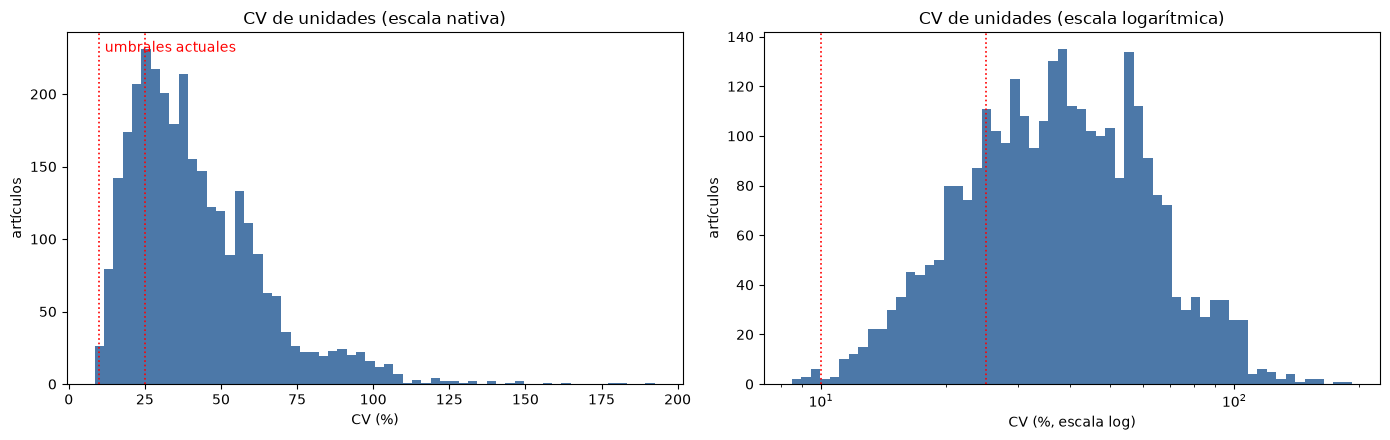

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cv_vals = cv_items["cv"]

axes[0].hist(cv_vals, bins=60, color="#4c78a8")
axes[0].set(title="CV de unidades (escala nativa)", xlabel="CV (%)", ylabel="artículos")

axes[1].hist(cv_vals, bins=np.logspace(np.log10(cv_vals.min()), np.log10(cv_vals.max()), 60), color="#4c78a8")
axes[1].set_xscale("log")
axes[1].set(title="CV de unidades (escala logarítmica)", xlabel="CV (%, escala log)", ylabel="artículos")

for ax in axes:
    for thr in seg["xyz_thresholds"]:
        ax.axvline(thr, color="red", linestyle=":", linewidth=1.2)
axes[0].annotate("umbrales actuales", (seg["xyz_thresholds"][0], 1.0), xycoords=("data", "axes fraction"),
                 xytext=(4, -14), textcoords="offset points", color="red")
fig.tight_layout()
plt.show()

### 4.2 · Relación del gasto con el CV

Gasto medio por artículo en deciles de CV (cada decil con el mismo número de artículos).

In [18]:
deciles = pd.qcut(cv_items["cv"].rank(method="first"), 10, labels=False) + 1
by_decile = cv_items.groupby(deciles).agg(
    cv_min=("cv", "min"), cv_max=("cv", "max"), items=("item_id", "size"),
    mean_spend=("spend", "mean"), median_spend=("spend", "median"),
).rename_axis("decil_cv")
display(by_decile)
print("correlación de Spearman CV–gasto:", round(cv_items["cv"].corr(cv_items["spend"], method="spearman"), 3))

,cv_min,cv_max,items,mean_spend,median_spend
decil_cv,,,,,
1,8.49,18.90,305,"76,639.08","44,976.35"
2,18.97,23.55,305,"56,953.46","36,025.48"
3,23.56,27.66,305,"67,131.41","38,210.96"
4,27.68,32.13,305,"52,951.86","34,783.28"
5,32.14,37.16,305,"62,599.65","35,217.50"
6,37.18,42.27,304,"58,940.17","33,861.44"
7,42.30,49.49,305,"51,255.54","28,303.86"
8,49.50,57.68,305,"67,002.95","38,372.64"
9,57.70,69.25,305,"50,454.09","29,352.12"


correlación de Spearman CV–gasto: -0.105


### 4.3 · Búsqueda de cortes

In [19]:
cuts = find_cv_cuts(
    cv_items["cv"], 
    cv_items["spend"], 
    n_cuts=N_CUTS, 
    min_share=MIN_SHARE, 
    resolution=RESOLUTION
    )
print(f"particiones evaluadas: {cuts['n_evaluated']:,} · factibles: {cuts['n_feasible']:,}")
print("cortes de CV (%):", [round(t, 2) for t in cuts["thresholds"]])
display(cuts["segments"].set_index("class"))

particiones evaluadas: 4,950 · factibles: 1,848
cortes de CV (%): [26.48, 55.4]


,n_items,share_items,cv_min,cv_max,mean_spend,total_spend,share_spend
class,,,,,,,
X,832,0.27,8.49,26.47,"67,789.82","56,401,132.40",0.31
Y,1515,0.50,26.49,55.39,"59,181.18","89,659,491.01",0.49
Z,702,0.23,55.40,192.52,"53,290.00","37,409,578.26",0.20


gasto medio descendente X → Z: True
mínimo de artículos por segmento: 23.0% (exigido: 20%)


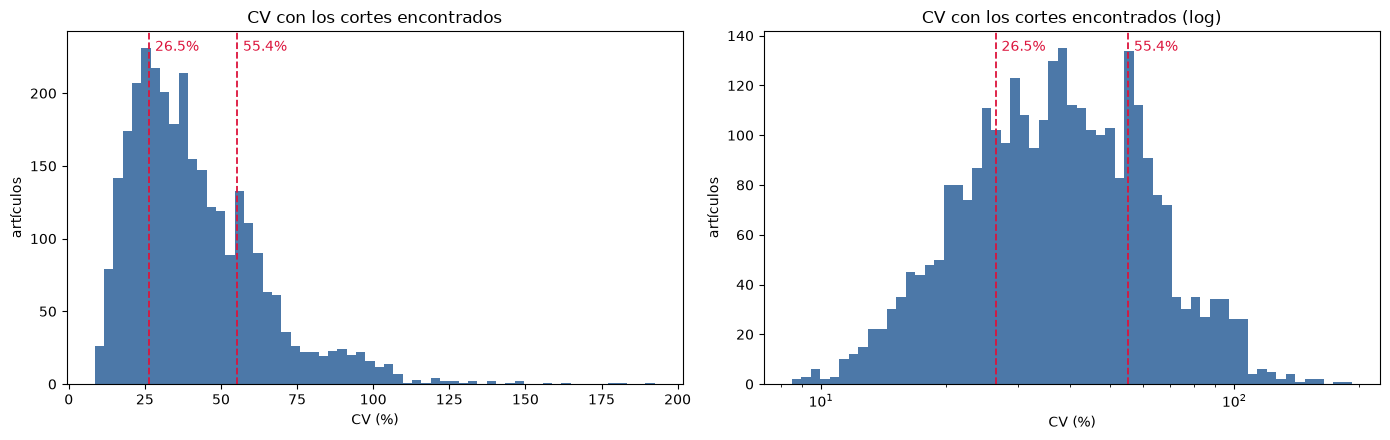

In [20]:
# Verificación: gasto medio descendente y mínimo de artículos por segmento.
segs = cuts["segments"]
print("gasto medio descendente X → Z:", segs["mean_spend"].is_monotonic_decreasing)
print(f"mínimo de artículos por segmento: {segs['share_items'].min():.1%} (exigido: {MIN_SHARE:.0%})")

# Los cortes sobre las distribuciones.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, log in zip(axes, (False, True)):
    bins = np.logspace(np.log10(cv_vals.min()), np.log10(cv_vals.max()), 60) if log else 60
    ax.hist(cv_vals, bins=bins, color="#4c78a8")
    if log:
        ax.set_xscale("log")
    for thr in cuts["thresholds"]:
        ax.axvline(thr, color="crimson", linestyle="--", linewidth=1.3)
        ax.annotate(f"{thr:.1f}%", (thr, 1.0), xycoords=("data", "axes fraction"),
                    xytext=(4, -14), textcoords="offset points", color="crimson")
    ax.set(title="CV con los cortes encontrados" + (" (log)" if log else ""), xlabel="CV (%)", ylabel="artículos")
fig.tight_layout()
plt.show()

### 4.4 · Clases resultantes

Clasificación XYZ con los nuevos cortes (`classify_xyz` aplica con 2 cortes) y cruce con ABC.

In [21]:
new_xyz = classify_xyz(matrix["cv"], cuts["thresholds"]) if N_CUTS == 2 else None
if new_xyz is not None:
    matrix["xyz_class_cv_cuts"] = new_xyz.to_numpy()
    cross = pd.crosstab(matrix["abc_class"].fillna("inactivo"), matrix["xyz_class_cv_cuts"].fillna("-"),
                        margins=True, margins_name="Total")
    assert cross.loc["Total", "Total"] == len(matrix)
    display(cross)
    print("% por fila")
    display((pd.crosstab(matrix["abc_class"].fillna("inactivo"), matrix["xyz_class_cv_cuts"].fillna("-"),
                         normalize="index", margins=True, margins_name="Total") * 100).round(1))
    print("% por columna")
    display((pd.crosstab(matrix["abc_class"].fillna("inactivo"), matrix["xyz_class_cv_cuts"].fillna("-"),
                         normalize="columns", margins=True, margins_name="Total") * 100).round(1))
else:
    print("classify_xyz solo admite 2 cortes; con otro N_CUTS usar los rangos de la tabla de segmentos.")

xyz_class_cv_cuts,X,Y,Z,Total
abc_class,,,,
A,207,297,121,625
B,338,604,245,1187
C,287,614,336,1237
Total,832,1515,702,3049


% por fila


xyz_class_cv_cuts,X,Y,Z
abc_class,,,
A,33.10,47.50,19.40
B,28.50,50.90,20.60
C,23.20,49.60,27.20
Total,27.30,49.70,23.00


% por columna


xyz_class_cv_cuts,X,Y,Z,Total
abc_class,,,,
A,24.90,19.60,17.20,20.50
B,40.60,39.90,34.90,38.90
C,34.50,40.50,47.90,40.60


In [22]:
active["cv"]

0      42.49
1      12.95
2      25.72
3      43.64
4      65.06
        ... 
3044   20.22
3045   34.33
3046   46.18
3047   25.02
3048   35.49
Name: cv, Length: 3049, dtype: float64

In [23]:
# XYZ: sobre el CV de los artículos activos.

xyz = classify_xyz(active["cv"], cuts["thresholds"])
# display(xyz.value_counts(dropna=False).rename("items").to_frame())

matrix = (
    metrics[["item_id", "active", "usage_units", "spend", "cv", "n_blocks"]]
    .merge(abc[["item_id", "cum_spend", "cum_pct_before", "abc_class"]], on="item_id", how="left")
    .merge(
        pd.DataFrame({"item_id": active["item_id"].to_numpy(), "xyz_class": xyz.to_numpy()}),
        on="item_id",
        how="left",
    )
    .sort_values(["active", "spend", "item_id"], ascending=[False, False, True])
    .reset_index(drop=True)
)

display(
    xyz.value_counts(dropna=False).rename("items").to_frame().style.set_caption("Clases XYZ"),
    matrix.head(10).style.set_caption("Matriz")
    )

,items
Y,1515
X,832
Z,702


,item_id,active,usage_units,spend,cv,n_blocks,cum_spend,cum_pct_before,abc_class,xyz_class
0,FOODS_3_120,True,290132.000000,1444850.105271,38.649821,56,1444850.105271,0.000000,A,Y
1,FOODS_3_586,True,873745.000000,1395728.806002,13.502093,65,2840578.911273,0.007875,A,X
2,FOODS_3_090,True,1008855.000000,1366337.795356,50.896951,65,4206916.706629,0.015483,A,Y
3,FOODS_3_202,True,286712.000000,1212799.692382,25.378006,65,5419716.399011,0.022930,A,X
4,FOODS_3_587,True,363263.000000,893838.151803,44.959768,65,6313554.550814,0.029540,A,Y
5,FOODS_3_252,True,540928.000000,823269.655651,18.203203,65,7136824.206465,0.034412,A,X
6,FOODS_3_555,True,462462.000000,736589.364402,19.014476,65,7873413.570867,0.038899,A,X
7,FOODS_3_444,True,109137.000000,719129.244241,103.242640,55,8592542.815108,0.042914,A,Z
8,HOBBIES_1_354,True,31143.000000,711937.128559,76.849040,31,9304479.943667,0.046833,A,Z
9,FOODS_1_096,True,92901.000000,645559.484986,74.986512,65,9950039.428653,0.050714,A,Z


In [24]:
# Matriz final: métricas + clase ABC + clase XYZ por artículo (inactivos al final, sin clase).

matrix["cell"] = np.where(matrix["active"], matrix["abc_class"].fillna("") + matrix["xyz_class"].fillna("-"), None)
display(matrix.head(10))
display(matrix.tail(5))

# Control: el mismo resultado debe salir de build_matrix (la función que usa el pipeline).
ref = build_matrix("check", source_data_artifact, start_d, end_d, seg, source_data_artifact["week_of_day"]).set_index("item_id")
mine = matrix.set_index("item_id").loc[ref.index]
same_abc = (mine["abc_class"].fillna("-") == ref["abc_class"].fillna("-")).all()
same_xyz = (mine["xyz_class"].fillna("-") == ref["xyz_class"].fillna("-")).all()
print("coincide con build_matrix · ABC:", same_abc, "· XYZ:", same_xyz)

,item_id,active,usage_units,spend,cv,n_blocks,cum_spend,cum_pct_before,abc_class,xyz_class,cell
0,FOODS_3_120,True,"290,132.00","1,444,850.11",38.65,56,"1,444,850.11",0.00,A,Y,AY
1,FOODS_3_586,True,"873,745.00","1,395,728.81",13.50,65,"2,840,578.91",0.01,A,X,AX
2,FOODS_3_090,True,"1,008,855.00","1,366,337.80",50.90,65,"4,206,916.71",0.02,A,Y,AY
3,FOODS_3_202,True,"286,712.00","1,212,799.69",25.38,65,"5,419,716.40",0.02,A,X,AX
4,FOODS_3_587,True,"363,263.00","893,838.15",44.96,65,"6,313,554.55",0.03,A,Y,AY
5,FOODS_3_252,True,"540,928.00","823,269.66",18.20,65,"7,136,824.21",0.03,A,X,AX
6,FOODS_3_555,True,"462,462.00","736,589.36",19.01,65,"7,873,413.57",0.04,A,X,AX
7,FOODS_3_444,True,"109,137.00","719,129.24",103.24,55,"8,592,542.82",0.04,A,Z,AZ
8,HOBBIES_1_354,True,"31,143.00","711,937.13",76.85,31,"9,304,479.94",0.05,A,Z,AZ
9,FOODS_1_096,True,"92,901.00","645,559.48",74.99,65,"9,950,039.43",0.05,A,Z,AZ


,item_id,active,usage_units,spend,cv,n_blocks,cum_spend,cum_pct_before,abc_class,xyz_class,cell
3044,HOBBIES_2_023,True,845.00,819.65,31.55,21,"183,468,058.29",1.00,C,Y,CY
3045,HOBBIES_2_065,True,"1,342.00",671.00,42.64,27,"183,468,729.29",1.00,C,Y,CY
3046,HOBBIES_2_047,True,"1,063.00",550.96,57.73,40,"183,469,280.25",1.00,C,Z,CZ
3047,HOBBIES_2_025,True,927.00,463.50,21.14,27,"183,469,743.75",1.00,C,X,CX
3048,HOBBIES_2_026,True,"1,991.00",457.93,65.18,27,"183,470,201.68",1.00,C,Z,CZ


coincide con build_matrix · ABC: False · XYZ: False


## 5 · Matriz cruzada ABC × XYZ

Recuento de artículos. `-` en XYZ = CV indefinido; `inactivo` en ABC = sin ventas en la ventana.

In [25]:
abc_lbl = matrix["abc_class"].fillna("inactivo")
xyz_lbl = matrix["xyz_class"].fillna("-")

counts = pd.crosstab(abc_lbl, xyz_lbl, margins=True, margins_name="Total")
assert counts.loc["Total", "Total"] == len(matrix), "la tabla debe sumar todos los artículos"
print(f"total de artículos en la tabla: {counts.loc['Total', 'Total']}")
display(counts)

total de artículos en la tabla: 3049


xyz_class,X,Y,Z,Total
abc_class,,,,
A,207,297,121,625
B,338,604,245,1187
C,287,614,336,1237
Total,832,1515,702,3049


In [26]:
# % sobre el total de cada fila (cómo se reparte cada clase ABC entre X, Y y Z).
by_row = pd.crosstab(abc_lbl, xyz_lbl, normalize="index", margins=True, margins_name="Total") * 100
print("% por fila")
display(by_row.round(2))

# % sobre el total de cada columna (cómo se reparte cada clase XYZ entre A, B y C).
by_col = pd.crosstab(abc_lbl, xyz_lbl, normalize="columns", margins=True, margins_name="Total") * 100
print("% por columna")
display(by_col.round(2))

% por fila


xyz_class,X,Y,Z
abc_class,,,
A,33.12,47.52,19.36
B,28.48,50.88,20.64
C,23.20,49.64,27.16
Total,27.29,49.69,23.02


% por columna


xyz_class,X,Y,Z,Total
abc_class,,,,
A,24.88,19.60,17.24,20.50
B,40.62,39.87,34.90,38.93
C,34.50,40.53,47.86,40.57


## 6 · Caracterización de los grupos ABC × XYZ

El perfil se calcula con `groupby` directamente sobre los totales por artículo (`spend`, `usage_units`) y las medidas por artículo de la sección 2, en tres niveles con las mismas columnas: global, por clase (ABC y XYZ) y por grupo homogéneo (AX … CZ).

`mean_cv` y `median_cv` son estadísticos de los CV de los artículos (bloques de 28 días sobre toda la ventana), no el CV de la demanda agregada del grupo.

In [27]:
# Base: una fila por artículo activo con sus clases y medidas.
extra = ["item_id", "zero_share", "mean_daily_units", "median_daily_units"]
groups = matrix.loc[matrix["active"], ["item_id", "abc_class", "xyz_class", "usage_units", "spend", "cv"]].merge(
    metrics[extra], on="item_id"
)
groups["xyz_class"] = groups["xyz_class"].fillna("-")   # "-" = CV indefinido
groups["group"] = groups["abc_class"] + groups["xyz_class"]

total_items = len(groups)
total_spend = groups["spend"].sum()
total_usage = groups["usage_units"].sum()
print(f"n_items: {total_items} · spend: {total_spend:,.0f} · usage_units: {total_usage:,.0f}")
display(groups.head())

n_items: 3049 · spend: 183,470,202 · usage_units: 63,933,886


,item_id,abc_class,xyz_class,usage_units,spend,cv,zero_share,mean_daily_units,median_daily_units,group
0,FOODS_3_120,A,Y,"290,132.00","1,444,850.11",38.65,0.01,183.98,185.00,AY
1,FOODS_3_586,A,X,"873,745.00","1,395,728.81",13.50,0.00,480.08,466.00,AX
2,FOODS_3_090,A,Y,"1,008,855.00","1,366,337.80",50.90,0.12,554.32,556.00,AY
3,FOODS_3_202,A,X,"286,712.00","1,212,799.69",25.38,0.05,157.53,156.00,AX
4,FOODS_3_587,A,Y,"363,263.00","893,838.15",44.96,0.03,199.60,220.00,AY


### 6.1 · Perfil global, por clase y por grupo

In [28]:
def profile_by(df, by):
    """Perfil de los artículos de `df` agrupados por `by` (columna o arreglo), sobre sus totales."""
    out = df.groupby(by).agg(
        n_items=("item_id", "size"),
        spend=("spend", "sum"),
        usage_units=("usage_units", "sum"),
        mean_spend=("spend", "mean"),
        median_spend=("spend", "median"),
        median_usage_units=("usage_units", "median"),
        mean_cv=("cv", "mean"),
        median_cv=("cv", "median"),
        mean_zero_share=("zero_share", "mean"),
        median_zero_share=("zero_share", "median"),
    )
    out["pct_items"] = out["n_items"] / total_items * 100
    out["pct_spend"] = out["spend"] / total_spend * 100
    out["pct_usage_units"] = out["usage_units"] / total_usage * 100
    return out[[
        "n_items", "pct_items", "spend", "pct_spend", "usage_units", "pct_usage_units",
        "mean_spend", "median_spend", "median_usage_units",
        "mean_cv", "median_cv", "mean_zero_share", "median_zero_share",
    ]]

profile = pd.concat(
    {
        "global": profile_by(groups, np.repeat("Total", total_items)),
        "abc_class": profile_by(groups, "abc_class"),
        "xyz_class": profile_by(groups, "xyz_class"),
        "group": profile_by(groups, "group"),
    },
    names=["level", "class"],
)

# Control: en cada nivel las clases reparten exactamente el total.
for level, part in profile.groupby(level="level"):
    assert part["n_items"].sum() == total_items, level
    assert np.isclose(part["pct_items"].sum(), 100) and np.isclose(part["pct_spend"].sum(), 100), level
    assert np.isclose(part["pct_usage_units"].sum(), 100), level
assert np.isclose(profile.loc["global", "spend"].iloc[0], total_spend)

fmt = {col: "{:,.1f}" for col in profile.columns}
fmt.update({"n_items": "{:,}", "spend": "{:,.0f}", "usage_units": "{:,.0f}", "mean_spend": "{:,.0f}",
            "median_spend": "{:,.0f}", "median_usage_units": "{:,.0f}", "mean_zero_share": "{:.3f}",
            "median_zero_share": "{:.3f}"})
display(profile.style.format(fmt).set_caption("Perfil: global, ABC, XYZ y grupos ABC × XYZ"))

### 6.2 · Matriz cruzada ABC × XYZ: % de `spend`

In [29]:
pct_spend = pd.pivot_table(groups, index="abc_class", columns="xyz_class", values="spend",
                           aggfunc="sum", margins=True, margins_name="Total") / total_spend * 100
assert np.isclose(pct_spend.loc["Total", "Total"], 100)
display(pct_spend.style.format("{:,.1f}", na_rep="–").set_caption("% de spend por grupo ABC × XYZ"))

xyz_class,X,Y,Z,Total
abc_class,,,,
A,19.5,28.9,11.7,60.0
B,8.8,15.1,6.1,30.0
C,2.5,4.9,2.7,10.0
Total,30.7,48.9,20.4,100.0


### 6.3 · Radares de medianas por grupo

Cada eje es la mediana del grupo dividida por la mediana de todos los artículos; el cuadrado discontinuo de valor 1.0 es el perfil global.

,median_spend,median_usage_units,median_cv,median_zero_share
class,,,,
AX,3.47,3.19,0.55,0.06
AY,3.86,3.81,1.01,0.57
AZ,3.75,3.70,1.79,2.08
BX,1.33,1.30,0.57,0.14
BY,1.25,1.24,1.02,0.76
BZ,1.22,1.33,1.76,2.28
CX,0.46,0.50,0.55,0.50
CY,0.41,0.42,1.03,1.68
CZ,0.42,0.43,1.83,3.17


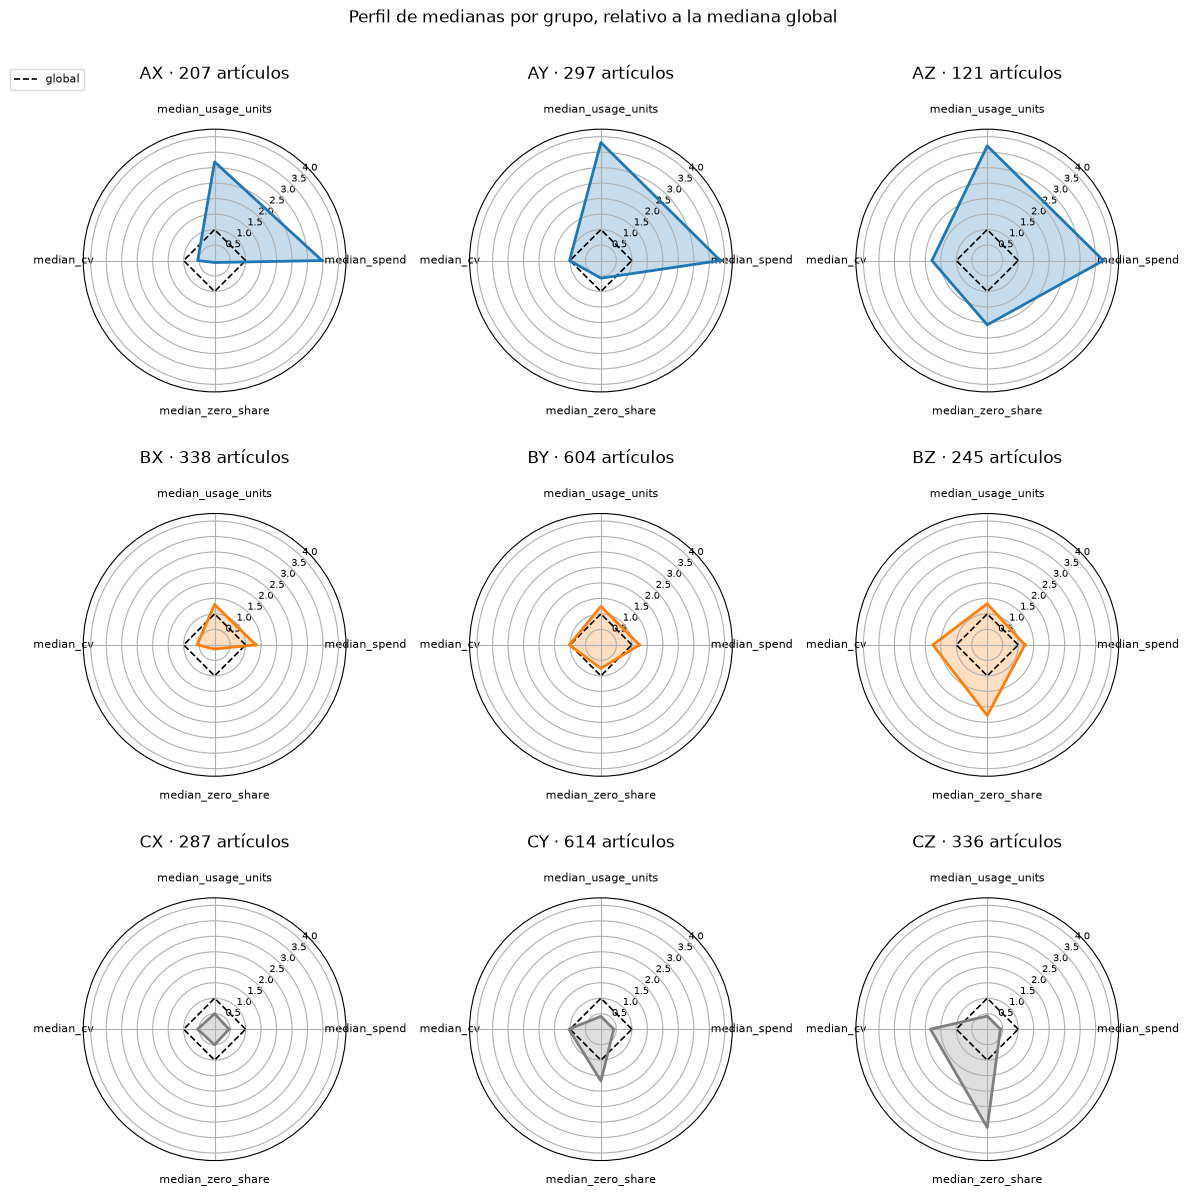

In [30]:
radar_cols = ["median_spend", "median_usage_units", "median_cv", "median_zero_share"]
global_median = profile.loc["global"].iloc[0][radar_cols]
ratios = profile.loc["group", radar_cols] / global_median
order = [a + x for a in "ABC" for x in "XYZ"]
ratios = ratios.reindex([g for g in order if g in ratios.index])
display(ratios.style.format("{:.2f}").set_caption("mediana del grupo / mediana global"))

angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False)
closed = np.r_[angles, angles[0]]
top = ratios.to_numpy().max() * 1.1

fig, axes = plt.subplots(3, 3, figsize=(12, 12), subplot_kw={"projection": "polar"})
for ax, grp in zip(axes.flat, order):
    if grp not in ratios.index:
        ax.set_visible(False)
        continue
    vals = ratios.loc[grp].to_numpy()
    ax.plot(closed, np.ones(len(closed)), color="black", linestyle="--", linewidth=1.2, label="global")
    ax.plot(closed, np.r_[vals, vals[0]], color=colors[grp[0]], linewidth=2)
    ax.fill(closed, np.r_[vals, vals[0]], color=colors[grp[0]], alpha=0.25)
    ax.set_xticks(angles)
    ax.set_xticklabels(radar_cols, fontsize=8)
    ax.set_ylim(0, top)
    ax.set_rlabel_position(45)
    ax.tick_params(axis="y", labelsize=7)
    ax.set_title(f"{grp} · {int(profile.loc[('group', grp), 'n_items']):,} artículos", pad=18)
axes.flat[0].legend(loc="upper left", bbox_to_anchor=(-0.3, 1.25), fontsize=8)
fig.suptitle("Perfil de medianas por grupo, relativo a la mediana global", y=1.0)
fig.tight_layout()
if SAVE_FIGURES:
    out = Path("reports/figures")
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "eda_five_years_radar.png", dpi=150, bbox_inches="tight")
    print("figura guardada en", out / "eda_five_years_radar.png")
plt.show()

<b> NOTA: </b>

Revizar como se trataron los ceros de los grupos AZ, BZ, CY y CZ y para los proximos pasos calcular la fuerza estacional y añadirla a los segmento o evaluar si mi planteamienot para el analiste inter e intra anual lo corrije

### 6.4 · Diagnóstico de ceros

Los grupos AZ, BZ, CY y CZ tienen una mediana de `zero_share` muy por encima de la global. Un cero del artículo agregado es un día con dato en el que **todas** las tiendas con dato vendieron 0. Cada día con cero se asigna a una hipótesis:

| Componente | Hipótesis |
|---|---|
| `leading` | Arranque: ceros entre el primer día con precio y la primera venta. El prelanzamiento ya es NaN y no cuenta. |
| `trailing` | Ruptura de demanda: ceros después de la última venta (el artículo dejó de venderse). |
| `long_run` | Escasez aislada o falta de surtido: rachas internas de al menos `LONG_RUN` días activos. |
| `short` | De verdad no se compró: ceros internos sueltos o en rachas cortas (demanda intermitente). |

También se mide cuántas tiendas tienen dato cada día (`mean_active_stores`): con pocas tiendas, el agregado se comporta como una serie de una sola tienda y acumula ceros. Los días NaN se saltan: una racha se mide en días activos.

In [31]:
LONG_RUN = 7  # días activos seguidos con cero para hablar de racha larga; el precio es semanal

series_data = load_interim(cfg, last_day, series_level=True)
assert np.array_equal(np.sort(series_data["series_index"]["item_id"].unique()), item_ids.astype(str))
stores = active_stores_by_item(series_data["units"], series_data["series_index"])
del series_data

runs = zero_runs(source_data_artifact, start_d, end_d)
zeros = zero_breakdown(source_data_artifact, start_d, end_d, LONG_RUN, active_stores=stores, runs=runs)
zeros = zeros.merge(groups[["item_id", "group"]], on="item_id")
parts = ["leading", "short", "long_run", "trailing"]
assert (zeros[parts].sum(axis=1) == zeros["zero_days"]).all(), "los componentes deben sumar los ceros"
print(f"rachas de ceros: {len(runs):,} · artículos con algún cero: {(zeros['zero_days'] > 0).sum():,}")
display(zeros.head())

rachas de ceros: 237,143 · artículos con algún cero: 3,049


,item_id,active_days,zero_days,leading,trailing,long_run,short,n_long_runs,max_internal_run,mean_active_stores,group
0,FOODS_1_001,1820,188,0,0,151,37,5,79,10.00,CY
1,FOODS_1_002,1820,76,0,0,0,76,0,2,10.00,BX
2,FOODS_1_003,1820,31,0,0,0,31,0,2,10.00,BX
3,FOODS_1_004,1542,149,4,0,114,31,5,54,10.00,AY
4,FOODS_1_005,1820,436,84,0,275,77,17,60,10.00,BZ


In [32]:
item_groups = groups.set_index("item_id")["group"]
group_order = [g for g in CELL_LABELS if g in set(item_groups)]

In [33]:
runs["position"].unique()

<ArrowStringArray>
['internal', 'leading', 'trailing']
Length: 3, dtype: str

In [34]:
runs[runs["item_id"] == "FOODS_1_001"]

,item_id,position,start_d,end_d,length
0,FOODS_1_001,internal,189,189,1
1,FOODS_1_001,internal,192,270,79
2,FOODS_1_001,internal,273,276,4
3,FOODS_1_001,internal,331,331,1
4,FOODS_1_001,internal,697,697,1
5,FOODS_1_001,internal,1006,1006,1
6,FOODS_1_001,internal,1018,1018,1
7,FOODS_1_001,internal,1020,1022,3
8,FOODS_1_001,internal,1024,1049,26
9,FOODS_1_001,internal,1051,1052,2


In [35]:
groups

,item_id,abc_class,xyz_class,usage_units,spend,cv,zero_share,mean_daily_units,median_daily_units,group
0,FOODS_3_120,A,Y,"290,132.00","1,444,850.11",38.65,0.01,183.98,185.00,AY
1,FOODS_3_586,A,X,"873,745.00","1,395,728.81",13.50,0.00,480.08,466.00,AX
2,FOODS_3_090,A,Y,"1,008,855.00","1,366,337.80",50.90,0.12,554.32,556.00,AY
3,FOODS_3_202,A,X,"286,712.00","1,212,799.69",25.38,0.05,157.53,156.00,AX
4,FOODS_3_587,A,Y,"363,263.00","893,838.15",44.96,0.03,199.60,220.00,AY
...,...,...,...,...,...,...,...,...,...,...
3044,HOBBIES_2_023,C,Y,845.00,819.65,31.55,0.34,1.42,1.00,CY
3045,HOBBIES_2_065,C,Y,"1,342.00",671.00,42.64,0.23,1.75,1.00,CY
3046,HOBBIES_2_047,C,Z,"1,063.00",550.96,57.73,0.50,0.94,1.00,CZ
3047,HOBBIES_2_025,C,X,927.00,463.50,21.14,0.33,1.21,1.00,CX


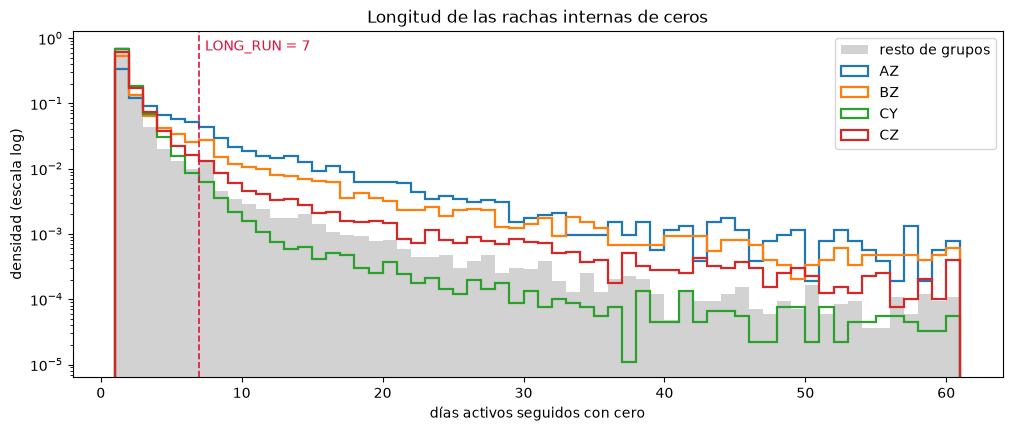

,count,mean,std,min,50%,90%,99%,max
group,,,,,,,,
AX,"2,600.0",1.8,3.3,1.0,1.0,3.0,13.0,77.0
AY,"7,107.0",4.8,13.0,1.0,2.0,9.0,53.0,359.0
AZ,"5,295.0",8.2,19.9,1.0,3.0,17.0,86.1,386.0
BX,"13,702.0",1.3,1.3,1.0,1.0,2.0,6.0,56.0
BY,"32,847.0",2.8,7.5,1.0,1.0,5.0,32.0,306.0
BZ,"15,121.0",6.4,21.9,1.0,1.0,12.0,90.0,745.0
CX,"27,938.0",1.4,1.0,1.0,1.0,2.0,5.0,48.0
CY,"90,899.0",1.9,4.5,1.0,1.0,3.0,11.0,183.0
CZ,"40,098.0",4.1,18.1,1.0,1.0,5.0,64.0,"1,249.0"


In [36]:
# Longitud de las rachas internas: base para fijar LONG_RUN.
focus = ["AZ", "BZ", "CY", "CZ"]
internal = runs[runs["position"] == "internal"].merge(groups[["item_id", "group"]], on="item_id")
bins = np.arange(1, 62)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(internal.loc[~internal["group"].isin(focus), "length"], bins=bins, density=True, color="grey",
        alpha=0.35, label="resto de grupos")
for g in focus:
    ax.hist(internal.loc[internal["group"] == g, "length"], bins=bins, density=True, histtype="step",
            linewidth=1.6, label=g)
ax.axvline(LONG_RUN, color="crimson", linestyle="--", linewidth=1.2)
ax.annotate(f"LONG_RUN = {LONG_RUN}", (LONG_RUN, 1.0), xycoords=("data", "axes fraction"), xytext=(4, -14),
            textcoords="offset points", color="crimson")
ax.set_yscale("log")
ax.set(title="Longitud de las rachas internas de ceros", xlabel="días activos seguidos con cero",
       ylabel="densidad (escala log)")
ax.legend()
plt.show()
display(internal.groupby("group")["length"].describe(percentiles=[0.5, 0.9, 0.99]).reindex(group_order)
        .style.format("{:,.1f}").set_caption("Longitud de las rachas internas por grupo"))

In [37]:
internal.loc[~internal["group"].isin(focus)]

,item_id,position,start_d,end_d,length,group
34,FOODS_1_002,internal,128,128,1,BX
35,FOODS_1_002,internal,140,140,1,BX
36,FOODS_1_002,internal,160,160,1,BX
37,FOODS_1_002,internal,171,171,1,BX
38,FOODS_1_002,internal,240,240,1,BX
...,...,...,...,...,...,...
235295,HOUSEHOLD_2_515,internal,1917,1917,1,CX
235296,HOUSEHOLD_2_515,internal,1919,1923,5,CX
235297,HOUSEHOLD_2_515,internal,1926,1926,1,CX
235298,HOUSEHOLD_2_515,internal,1929,1931,3,CX


,n_items,median_zero_share,median_leading,median_short,median_long_run,median_trailing,pct_items_trailing,pct_items_long_run,median_active_stores
group,,,,,,,,,
AX,207,0.7,0.0,0.4,0.0,0.0,0.0,29.5,10.0
AY,297,5.9,0.0,1.6,3.2,0.0,1.3,79.5,10.0
AZ,121,21.4,0.0,3.4,16.4,0.0,10.7,94.2,10.0
BX,338,1.4,0.0,0.9,0.0,0.0,1.2,22.2,10.0
BY,604,7.9,0.0,2.8,3.8,0.0,1.5,75.0,9.9
BZ,245,23.5,0.0,4.2,17.6,0.0,2.0,95.1,10.0
CX,287,5.2,0.2,4.5,0.0,0.0,6.3,23.3,9.9
CY,614,17.3,0.1,9.9,3.4,0.0,6.2,75.2,9.8
CZ,336,32.7,0.1,9.2,20.0,0.0,5.1,94.3,9.8


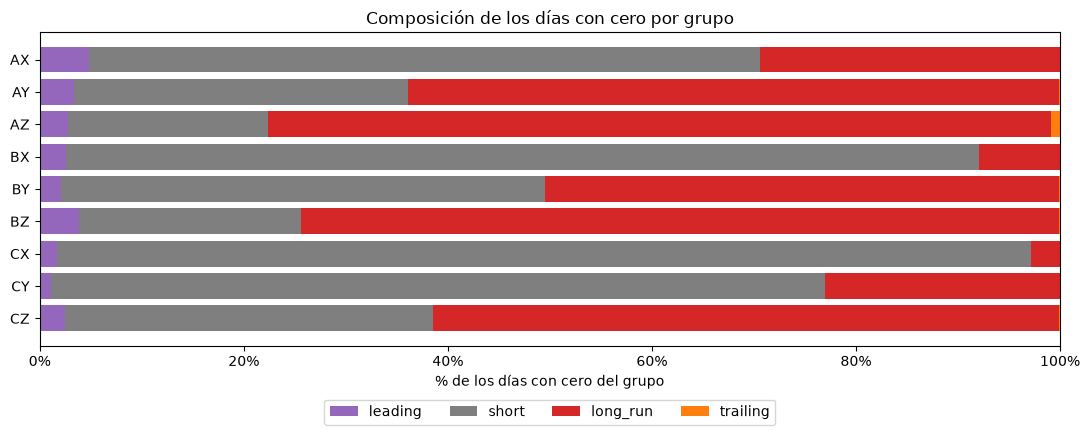

In [38]:
# De todos los ceros de cada grupo, qué parte viene de cada componente.
composition = zeros.groupby("group")[parts].sum().reindex(group_order)
composition = composition.div(composition.sum(axis=1), axis=0) * 100

pct_days = zeros[parts].div(zeros["active_days"], axis=0) * 100
summary_zeros = pct_days.assign(
    group=zeros["group"],
    zero_share=zeros["zero_days"] / zeros["active_days"] * 100,
    with_trailing=(zeros["trailing"] > 0) * 100,
    with_long_run=(zeros["n_long_runs"] > 0) * 100,
    mean_active_stores=zeros["mean_active_stores"],
).groupby("group").agg(
    n_items=("zero_share", "size"),
    median_zero_share=("zero_share", "median"),
    median_leading=("leading", "median"),
    median_short=("short", "median"),
    median_long_run=("long_run", "median"),
    median_trailing=("trailing", "median"),
    pct_items_trailing=("with_trailing", "mean"),
    pct_items_long_run=("with_long_run", "mean"),
    median_active_stores=("mean_active_stores", "median"),
).reindex(group_order)
display(summary_zeros.style.format({c: "{:,}" if c == "n_items" else "{:.1f}" for c in summary_zeros.columns})
        .set_caption("Ceros por grupo: medianas en % de días activos y % de artículos con cada patrón"))

fig, ax = plt.subplots(figsize=(11, 4.5))
left = np.zeros(len(composition))
part_colors = {"leading": "#9467bd", "short": "#7f7f7f", "long_run": "#d62728", "trailing": "#ff7f0e"}
for p in parts:
    ax.barh(composition.index, composition[p], left=left, color=part_colors[p], label=p)
    left += composition[p].to_numpy()
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set(title="Composición de los días con cero por grupo", xlabel="% de los días con cero del grupo", xlim=(0, 100))
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()
plt.show()

In [39]:
# Sensibilidad: ¿cuántos Z dejan de serlo sin los ceros de arranque, finales y de rachas largas?
# Con block28, compute_cv descarta entero el bloque de 28 días que contiene un día quitado.
units_clean = drop_zero_runs(source_data_artifact["item_units"], item_ids, runs,
                             {"leading", "trailing", "long_run"}, LONG_RUN)
cv_clean = compute_cv(units_clean, start_d, end_d, seg["cv_aggregation"], seg["cv_min_blocks"])
sens = groups[["item_id", "group", "xyz_class", "cv"]].merge(
    pd.DataFrame({"item_id": item_ids, "cv_clean": cv_clean["cv"].to_numpy(),
                  "n_blocks_clean": cv_clean["n_blocks"].to_numpy()}), on="item_id")
sens["xyz_clean"] = classify_xyz(sens["cv_clean"], cuts["thresholds"]).fillna("-").to_numpy()

sens_crosstab = pd.crosstab(sens["xyz_class"], sens["xyz_clean"], margins=True, margins_name="Total")

# Suma elementos en la diagonal principal
mantiene = np.array(sens_crosstab)[:3,:3].trace()

# Suma elementos por debajo de la diagonal principal
mejora = np.sum(np.tril(np.array(sens_crosstab)[:3,:3], k=-1))

# Suma elementos por encima de la diagonal principal
empeora = np.sum(np.triu(np.array(sens_crosstab)[:3,:3], k=1))

df_transiciones = pd.DataFrame(
    index=["mantiene", "mejora", "empeora"],
    columns=["values"],
    data =[
        [mantiene], 
        [mejora], 
        [empeora]
        ]
)

display(
    sens_crosstab.style.set_caption("XYZ con los ceros (filas) frente a XYZ sin ellos (columnas), mismos umbrales"),
    df_transiciones.style.set_caption("Mantiene, mejora, empeora")
    )

by_group = sens.groupby("group").agg(
    median_cv=("cv", "median"), median_cv_clean=("cv_clean", "median"),
    pct_z=("xyz_class", lambda s: (s == "Z").mean() * 100),
    pct_z_clean=("xyz_clean", lambda s: (s == "Z").mean() * 100),
    pct_cv_undefined=("xyz_clean", lambda s: (s == "-").mean() * 100),
).reindex(group_order)
display(by_group.style.format("{:.1f}").set_caption("CV y % de Z por grupo, con y sin esos ceros"))

xyz_clean,X,Y,Z,Total
xyz_class,,,,
X,831,1,0,832
Y,474,1041,0,1515
Z,148,408,146,702
Total,1453,1450,146,3049


,values
mantiene,2018
mejora,1030
empeora,1


,median_cv,median_cv_clean,pct_z,pct_z_clean,pct_cv_undefined
group,,,,,
AX,20.3,18.7,0.0,0.0,0.0
AY,37.7,29.6,0.0,0.0,0.0
AZ,66.4,42.2,100.0,20.7,0.0
BX,21.1,20.4,0.0,0.0,0.0
BY,37.9,28.6,0.0,0.0,0.0
BZ,65.2,39.5,100.0,18.0,0.0
CX,20.5,20.2,0.0,0.0,0.0
CY,38.4,30.0,0.0,0.0,0.0
CZ,68.2,38.0,100.0,22.9,0.0


In [40]:
sens["xyz_class"].value_counts(normalize=True)

xyz_class
Y   0.50
X   0.27
Z   0.23
Name: proportion, dtype: float64

In [41]:
sens["xyz_clean"].value_counts(normalize=True)

xyz_clean
X   0.48
Y   0.48
Z   0.05
Name: proportion, dtype: float64

### 6.5 · Grupos crudos frente a grupos sin ceros de arranque, finales ni rachas largas

Mismo cruce ABC × XYZ que alimenta los radares, en dos versiones:

- **Crudo:** la clase XYZ con el CV de los cinco años tal cual.
- **Limpio:** la clase XYZ con el CV sin los ceros `leading`, `trailing` y `long_run` (`LONG_RUN` días o más), es decir, `xyz_clean` de la sensibilidad anterior.

Se aplican **los mismos umbrales del CV** (`cuts["thresholds"]`), así que la diferencia viene solo de quitar esos ceros. ABC no cambia: los días con cero no aportan gasto, así que solo se mueve XYZ y, en la conjunta, los movimientos quedan dentro de cada clase ABC (AZ → AY, BY → BX…). No reemplaza a los radares: es una comparación de cuántos artículos quedan en cada grupo. Depende de `LONG_RUN`.

,n_crudo,n_limpio,diferencia,se_quedan,pct_items_crudo,pct_items_limpio,pct_spend_crudo,pct_spend_limpio
AX,207,322,115,207,6.8,10.6,19.5,29.9
AY,297,278,-19,205,9.7,9.1,28.9,27.8
AZ,121,25,-96,25,4.0,0.8,11.7,2.3
BX,338,596,258,337,11.1,19.5,8.8,15.2
BY,604,547,-57,395,19.8,17.9,15.1,13.7
BZ,245,44,-201,44,8.0,1.4,6.1,1.1
CX,287,535,248,287,9.4,17.5,2.5,4.6
CY,614,625,11,441,20.1,20.5,4.9,4.8
CZ,336,77,-259,77,11.0,2.5,2.7,0.6
Total,"3,049","3,049",0,"2,018",100.0,100.0,100.0,100.0


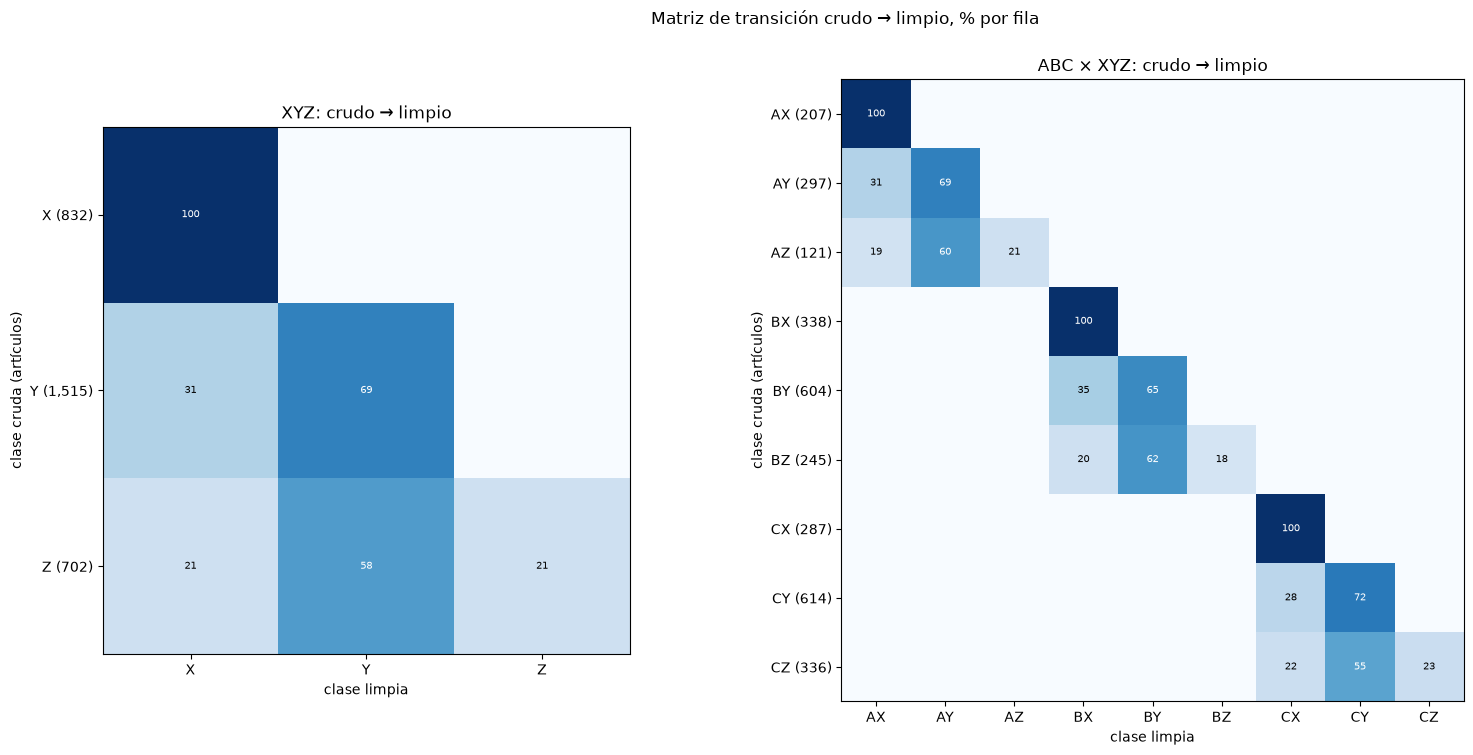

In [42]:
def heatmap_pct(ax, counts, title, xlabel, ylabel):
    """Dibuja una matriz de conteos como % por fila, con el total de cada fila en la etiqueta."""
    pct = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
    ax.imshow(pct.fillna(0).to_numpy(), cmap="Blues", vmin=0, vmax=100)
    for i in range(pct.shape[0]):
        for j in range(pct.shape[1]):
            v = pct.iat[i, j]
            if v >= 1:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if v > 50 else "black")
    ax.set_xticks(range(pct.shape[1]), pct.columns)
    ax.set_yticks(range(pct.shape[0]), [f"{c} ({n:,})" for c, n in counts.sum(axis=1).items()])
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)


# Grupo limpio: misma clase ABC y XYZ con el CV sin ceros de arranque, finales ni rachas largas.
regroup = sens[["item_id", "group", "xyz_class", "xyz_clean"]].merge(
    groups[["item_id", "abc_class", "spend"]], on="item_id")
regroup["group_clean"] = regroup["abc_class"] + regroup["xyz_clean"]
extra = sorted((set(regroup["group"]) | set(regroup["group_clean"])) - set(group_order))  # p. ej. "A-"
order_rg = group_order + extra

n_rg, spend_rg = len(regroup), regroup["spend"].sum()
raw_n = regroup["group"].value_counts().reindex(order_rg, fill_value=0)
clean_n = regroup["group_clean"].value_counts().reindex(order_rg, fill_value=0)
stay = regroup[regroup["group"] == regroup["group_clean"]]["group"].value_counts().reindex(order_rg, fill_value=0)
regroup_table = pd.DataFrame({
    "n_crudo": raw_n,
    "n_limpio": clean_n,
    "diferencia": clean_n - raw_n,
    "se_quedan": stay,
    "pct_items_crudo": raw_n / n_rg * 100,
    "pct_items_limpio": clean_n / n_rg * 100,
    "pct_spend_crudo": regroup.groupby("group")["spend"].sum().reindex(order_rg, fill_value=0) / spend_rg * 100,
    "pct_spend_limpio": regroup.groupby("group_clean")["spend"].sum().reindex(order_rg, fill_value=0) / spend_rg * 100,
})
regroup_table.loc["Total"] = regroup_table.sum()
assert regroup_table.loc["Total", "n_crudo"] == regroup_table.loc["Total", "n_limpio"] == n_rg
display(regroup_table.style.format({c: "{:,.0f}" for c in ["n_crudo", "n_limpio", "diferencia", "se_quedan"]}
                                   | {c: "{:.1f}" for c in regroup_table.columns if c.startswith("pct")})
        .set_caption("Artículos y gasto por grupo: crudo frente a limpio (mismos umbrales del CV)"))

# Matrices crudo → limpio. ABC es idéntica por construcción, así que solo XYZ y la conjunta.
assert (regroup["group"].str[0] == regroup["group_clean"].str[0]).all(), "ABC no debe cambiar"
xyz_order = XYZ_LABELS + sorted((set(regroup["xyz_class"]) | set(regroup["xyz_clean"])) - set(XYZ_LABELS))
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1, 2]})
for ax, (ref, tgt, labels, name) in zip(axes, [("xyz_class", "xyz_clean", xyz_order, "XYZ"),
                                               ("group", "group_clean", order_rg, "ABC × XYZ")]):
    counts = pd.crosstab(regroup[ref], regroup[tgt]).reindex(index=labels, columns=labels, fill_value=0)
    heatmap_pct(ax, counts, f"{name}: crudo → limpio", "clase limpia", "clase cruda (artículos)")
fig.suptitle("Matriz de transición crudo → limpio, % por fila", y=1.0)
fig.tight_layout()
plt.show()


#### Conclusión de la 6.5

- **Z casi desaparece:** pasa de 702 a 146 artículos (−79 %). AZ queda en 25 de 121, BZ en 44 de 245 y CZ en 77 de 336. La mayor parte de la variabilidad de Z viene de ceros estructurales (arranque, salida o rachas largas), no de demanda errática.
- **X casi se duplica:** de 832 a 1.453. Pasan a X el 31 % de los Y y el 21 % de los Z (AX 207 → 322, BX 338 → 596, CX 287 → 535).
- **En gasto el cambio es mayor en A:** AZ baja de 11,7 % a 2,3 % del gasto y AX sube de 19,5 % a 29,9 %.
- **Solo hay movimientos hacia clases más estables:** 2.018 artículos (66 %) mantienen su grupo, 1.030 mejoran y solo 1 empeora (BX → BY, al perder bloques).
- **Implicación:** la clase XYZ depende mucho de cómo se traten los ceros. Queda como hallazgo; la clasificación de los radares y de las secciones siguientes no cambia.

## 7 · Regla de selección de cortes ABC

Regla (aproximada): **A** con 10–20 % de los artículos y 60–80 % del gasto estimado; **B** con 20–30 % de los artículos y 20–30 % del gasto. `select_abc_cuts` recorre una grilla de cortes con paso 0,01 y elige el par con menor violación (puntos porcentuales fuera de los intervalos); entre empates, el más cercano al centro de los intervalos. Se minimiza la violación porque la curva de Pareto ata el % de artículos al % de gasto y la regla puede no tener solución exacta.

El gasto estimado es un proxy (unidades × precio de venta), no ganancia ni margen. Las secciones 3–6 siguen con los cortes elegidos a mano (`CUT_A`, `CUT_B`); aquí solo se comparan. La regla es la que se aplica en cada base del análisis interanual y en cada año del intraanual.

In [43]:
ABC_RULE = {
    "item_bounds": ((0.10, 0.20), (0.20, 0.30)),   # % de artículos de A y de B
    "spend_bounds": ((0.60, 0.80), (0.20, 0.30)),  # % del gasto de A y de B
    "step": 0.01,
}
abc_rule_global = select_abc_cuts(active["item_id"], active["spend"].to_numpy(), **ABC_RULE)
print("cortes de la regla:", abc_rule_global["cuts"], "· cortes elegidos a mano:", [CUT_A, CUT_B])

scen = abc_rule_global["scenarios"]
scen_cols = ["cut_A", "cut_B", "A_items_pct", "A_spend_pct", "B_items_pct", "B_spend_pct",
             "C_items_pct", "C_spend_pct", "violation"]
display(scen[scen_cols].head(10).style.format("{:.2f}").set_caption("Mejores escenarios según la regla"))
manual = scen[np.isclose(scen["cut_A"], CUT_A) & np.isclose(scen["cut_B"], CUT_B)]
display(manual[scen_cols].style.format("{:.2f}").set_caption("Escenario elegido a mano"))

cortes de la regla: [0.6, 0.83] · cortes elegidos a mano: [0.6, 0.9]


,cut_A,cut_B,A_items_pct,A_spend_pct,B_items_pct,B_spend_pct,C_items_pct,C_spend_pct,violation
0,0.60,0.83,20.50,60.04,25.88,22.98,53.62,16.98,0.50
1,0.60,0.84,20.50,60.04,27.52,23.97,51.98,15.99,0.50
2,0.60,0.82,20.50,60.04,24.27,21.96,55.23,18.00,0.50
3,0.60,0.85,20.50,60.04,29.22,24.97,50.28,14.99,0.50
4,0.60,0.81,20.50,60.04,22.76,20.97,56.74,18.99,0.50
5,0.60,0.80,20.50,60.04,21.29,19.98,58.22,19.99,0.52
6,0.59,0.82,19.74,59.04,25.02,22.96,55.23,18.00,0.96
7,0.59,0.83,19.74,59.04,26.63,23.98,53.62,16.98,0.96
8,0.59,0.84,19.74,59.04,28.27,24.97,51.98,15.99,0.96
9,0.59,0.81,19.74,59.04,23.52,21.97,56.74,18.99,0.96


,cut_A,cut_B,A_items_pct,A_spend_pct,B_items_pct,B_spend_pct,C_items_pct,C_spend_pct,violation
193,0.60,0.90,20.50,60.04,38.93,29.96,40.57,10.00,9.43


## 8 · Análisis interanual

### 8.1 · Base expansiva (planteamiento inicial)

- **Base expansiva:** Y2 ← Y1, Y3 ← prom(Y1, Y2), Y4 ← prom(Y1–Y3), Y5 ← prom(Y1–Y4). La base de cada artículo es el promedio de su gasto y de su CV anual en los años en que estuvo activo todo el año (como FR-016).
- **Cortes elegidos en la base y aplicados al año objetivo** (como train → test):
  - ABC: la regla de la sección 7 sobre el gasto de la base, convertida a fronteras de participación en el gasto. El año objetivo se clasifica por su participación, así que la proporción de clases puede moverse y la participación neutraliza el crecimiento de la cadena.
  - XYZ: `find_cv_cuts` (mismos `N_CUTS`, `MIN_SHARE` y `RESOLUTION` de la sección 4) sobre el CV de la base. Base y objetivo usan CV anual (bloques de 28 días), así que se pueden comparar.
- **PSI** sobre el % de artículos en los 9 grupos ABC × XYZ, solo con los artículos que tienen grupo en la base y en el objetivo. Los lanzados después (`new`) van aparte. Bandas (`psi_bands`): < 0,10 estable, 0,10–0,25 moderado, ≥ 0,25 cambio.
- **Matriz de transición** base × objetivo: muestra qué movimientos producen cada PSI.

Y5 entra solo como línea base descriptiva: nada de esta sección decide cortes, periodos ni modelos (Principio VI).

In [44]:
wod = source_data_artifact["week_of_day"]
CV_CUT_KW = {"n_cuts": N_CUTS, "min_share": MIN_SHARE, "resolution": RESOLUTION}

# De year_matrices solo se usan el gasto y el CV anuales; sus clases (cortes de la config) no.
year_mats = year_matrices(source_data_artifact, years, seg, wod)
prior = prior_years_map(list(years))
inter = {
    target: base_target_classes(year_mats, years, base, target, source_data_artifact, ABC_RULE,
                                EDA_PSI, CV_CUT_KW)
    for target, base in prior.items()
}
psi_table = pd.DataFrame([r["summary"] for r in inter.values()]).set_index("target")
display(psi_table.style.format({
    "cut_A": "{:.2f}", "cut_B": "{:.2f}", "share_A": "{:.5f}", "share_B": "{:.5f}",
    "cv_X": "{:.1f}", "cv_Z": "{:.1f}", "psi": "{:.3f}",
}).set_caption("PSI de los grupos ABC × XYZ por comparación, con los cortes de cada base"))

,base,cut_A,cut_B,share_A,share_B,cv_X,cv_Z,n_base,n_target,n_compared,n_new,n_no_target,psi,psi_band
target,,,,,,,,,,,,,,
Y2,Y1,0.60,0.82,0.00074,0.00039,14.4,49.6,1682,2112,1675,430,0,0.061,stable
Y3,Y1+Y2,0.60,0.83,0.00060,0.00029,14.8,53.4,2112,2525,2105,413,0,0.049,stable
Y4,Y1+Y2+Y3,0.60,0.82,0.00051,0.00025,16.5,48.4,2525,2890,2521,365,0,0.127,moderate
Y5,Y1+Y2+Y3+Y4,0.60,0.82,0.00043,0.00022,21.8,49.9,2890,3049,2890,159,0,0.231,moderate


In [45]:
prior

{'Y2': ['Y1'],
 'Y3': ['Y1', 'Y2'],
 'Y4': ['Y1', 'Y2', 'Y3'],
 'Y5': ['Y1', 'Y2', 'Y3', 'Y4']}

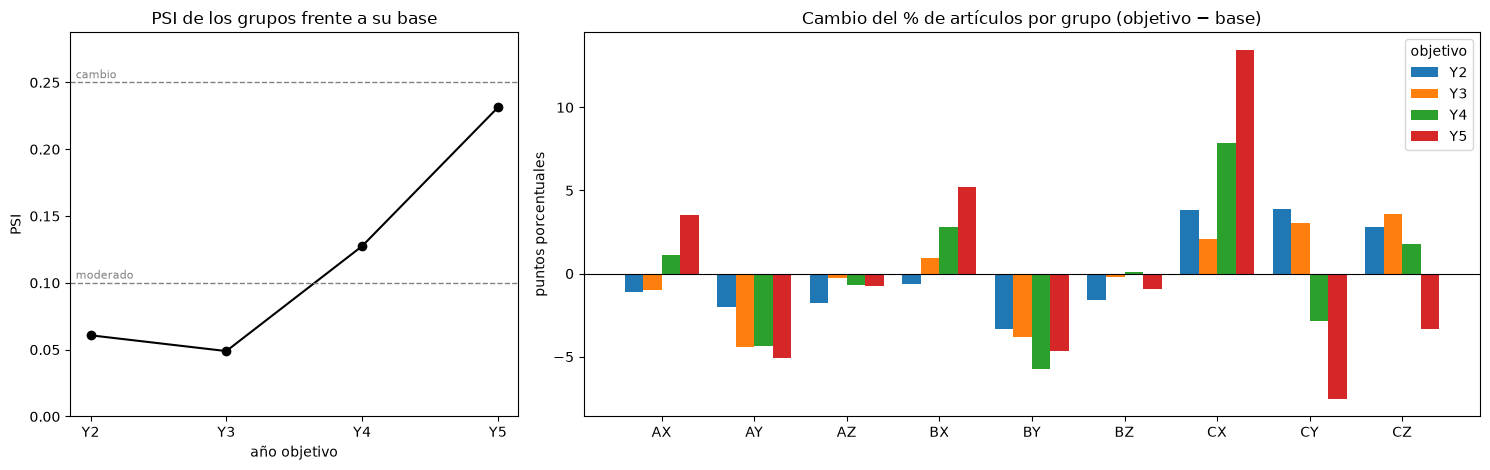

In [46]:
# % de artículos por grupo en la base y en el objetivo (población del PSI).
props = pd.concat({t: r["proportions"].set_index("cell") for t, r in inter.items()}, axis=1)
display(props.style.format("{:.1f}").set_caption("% de artículos por grupo: base y objetivo"))

bands = EDA_PSI["psi_bands"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.plot(psi_table.index, psi_table["psi"], marker="o", color="black")
for b, label in zip(bands, ("moderado", "cambio")):
    ax.axhline(b, color="grey", linestyle="--", linewidth=1)
    ax.annotate(label, (0, b), xycoords=("axes fraction", "data"), xytext=(4, 3), textcoords="offset points",
                color="grey", fontsize=8)
ax.set(title="PSI de los grupos frente a su base", xlabel="año objetivo", ylabel="PSI",
       ylim=(0, max(bands[1], psi_table["psi"].max()) * 1.15))

ax = axes[1]
x = np.arange(len(CELL_LABELS))
width = 0.8 / len(inter)
for k, (t, r) in enumerate(inter.items()):
    p = r["proportions"].set_index("cell").loc[CELL_LABELS]
    ax.bar(x + k * width, p["target_pct"] - p["base_pct"], width, label=t)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x + width * (len(inter) - 1) / 2, CELL_LABELS)
ax.set(title="Cambio del % de artículos por grupo (objetivo − base)", ylabel="puntos porcentuales")
ax.legend(title="objetivo")
fig.tight_layout()
if SAVE_FIGURES:
    out = Path("reports/figures")
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "eda_five_years_psi_interannual.png", dpi=150, bbox_inches="tight")
    print("figura guardada en", out / "eda_five_years_psi_interannual.png")
plt.show()

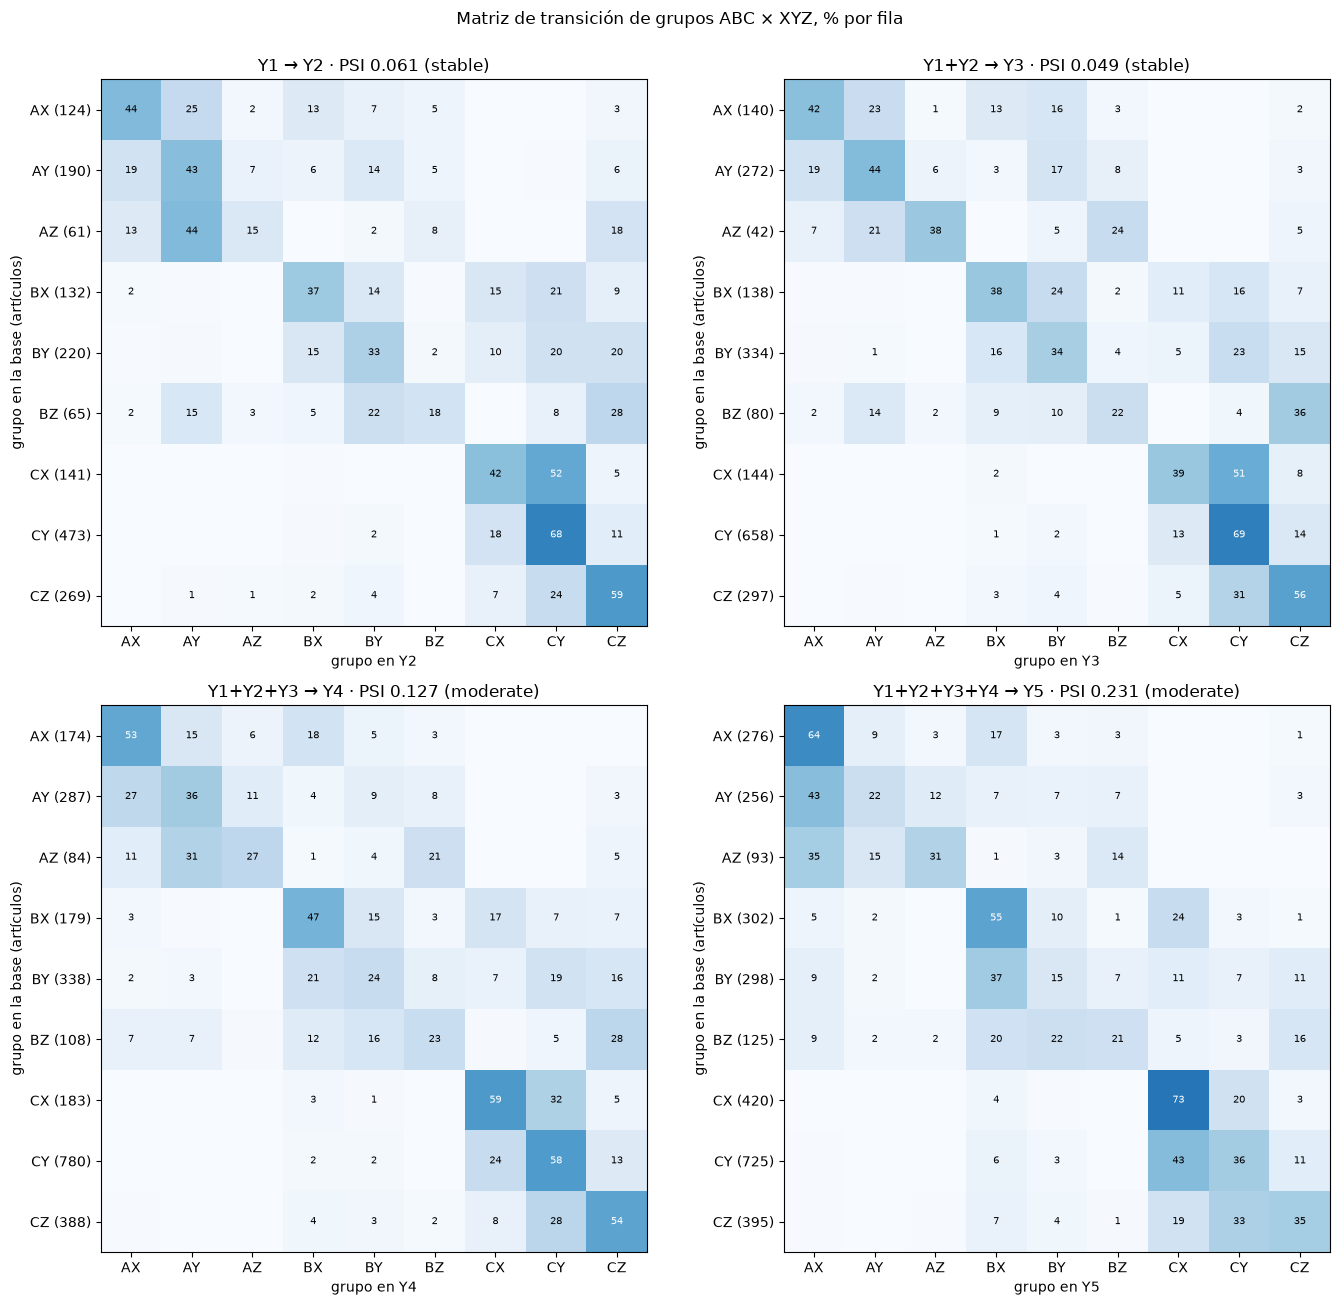

status,absent,both,new
Y2,937,1682,430
Y3,524,2112,413
Y4,159,2525,365
Y5,0,2890,159


tgt_cell,AX,AY,AZ,BX,BY,BZ,CX,CY,CZ,-
Y2,17,37,10,21,42,10,43,167,82,1
Y3,21,46,5,23,52,14,29,165,57,1
Y4,19,19,8,25,51,10,45,123,65,0
Y5,14,9,0,23,15,2,46,25,25,0


In [47]:
fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for ax, (t, r) in zip(axes.flat, inter.items()):
    it = r["items"]
    both = it[(it["status"] == "both") & it["ref_cell"].notna() & it["tgt_cell"].notna()]
    counts = pd.crosstab(both["ref_cell"], both["tgt_cell"]).reindex(
        index=CELL_LABELS, columns=CELL_LABELS, fill_value=0)
    assert counts.to_numpy().sum() == r["summary"]["n_compared"], t
    s = r["summary"]
    heatmap_pct(ax, counts, f"{s['base']} → {t} · PSI {s['psi']:.3f} ({s['psi_band']})",
                f"grupo en {t}", "grupo en la base (artículos)")
fig.suptitle("Matriz de transición de grupos ABC × XYZ, % por fila", y=1.0)
fig.tight_layout()
plt.show()

# Artículos fuera del PSI: lanzados después de la base (new) y su grupo en el año objetivo.
status = pd.DataFrame({t: r["items"]["status"].value_counts() for t, r in inter.items()}).T.fillna(0).astype(int)
display(status.style.set_caption("Estado de los artículos por comparación"))
new_cells = pd.DataFrame({
    t: r["items"].loc[r["items"]["status"] == "new", "tgt_cell"].fillna("-").value_counts()
    for t, r in inter.items()
}).T.reindex(columns=[*CELL_LABELS, "-"]).fillna(0).astype(int)
display(new_cells.style.set_caption("Grupo en el año objetivo de los artículos nuevos (fuera del PSI)"))

### 8.2 · Regla fija y mismos artículos

**Pregunta:** ¿cambia la composición de los grupos ABC × XYZ a lo largo de los años?

La 8.1 responde con dos sesgos de construcción que inflan la magnitud del cambio, aunque no su dirección:

1. **El promedio cambia la regla.** Promediar el CV de varios años sube el extremo bajo de la distribución, y `cv_X` pasa de 14,4 (base Y1) a 21,8 (base Y1–Y4). Ese corte, aplicado al CV de un solo año, deja como X a artículos que serían Y.
2. **El catálogo crece.** El año objetivo se clasifica por participación en el gasto, y los artículos activos pasan de 2.019 en Y1 a 3.049 en Y5. Con más artículos repartiéndose el gasto, la participación de cada uno baja y la clase A se encoge sin que los artículos cambien.

Recalcular sobre la ventana completa tampoco sirve: el CV de varios años incluye los cambios de nivel entre años y no es comparable con el CV anual.

**Método de la 8.2:**
- **Mismos artículos:** solo los activos todos los días de Y1 a Y5. La participación se calcula sobre el mismo grupo en la base y en el objetivo.
- **Sin promedios:** gasto y CV anuales en todas las comparaciones. Los cortes se eligen en la base con la misma regla de la 8.1 (`ABC_RULE` y `find_cv_cuts`) y se aplican al objetivo.
- **Dos bases:**
  - **Y1 fija** (cortes de Y1 para todos los años): cambio acumulado desde el inicio.
  - **Año anterior** (Yt−1 → Yt): velocidad del cambio.
- **Tres niveles:** ABC, XYZ y ABC × XYZ (los 9 grupos).

**Medidas** (`transition_stats`), sobre datos **pareados** (el mismo artículo en la base y en el objetivo). El PSI queda solo en la 8.1: compara poblaciones independientes, y aquí no lo son.

| Medida | Pregunta |
|---|---|
| κ de Cohen (plano) | ¿Cada artículo conserva su clase? Acuerdo descontado el azar; 1 = igual, 0 = como el azar |
| Stuart–Maxwell | ¿Cambió el % de artículos por clase? Homogeneidad marginal pareada (H0: mismos % en la base y en el objetivo) |
| `max_shift_pp` | ¿Cuánto? Mayor cambio del % de artículos de una clase, en puntos porcentuales |
| mantiene / mejora / empeora / mixto | En ABC y XYZ: diagonal, debajo (C → A, Z → X) y encima de la matriz. En ABC × XYZ el orden AX…CZ no es ordinal, así que cada artículo se mira en las dos dimensiones: mejora si sube en alguna sin bajar en la otra, empeora si baja sin subir, y es **mixto** si sube en una y baja en la otra (p. ej. AZ → BX) |

**Límites:**
- Stuart–Maxwell con n = 1.682 declara significativos cambios mínimos; se lee junto con `max_shift_pp`.
- El κ es plano (sin ponderar) aunque ABC y XYZ son ordinales: un salto A → C pesa igual que A → B.
- El panel cubre solo los artículos activos los cinco años: los lanzados después de Y1 no entran.

artículos activos los cinco años: 1,682 de 3,049


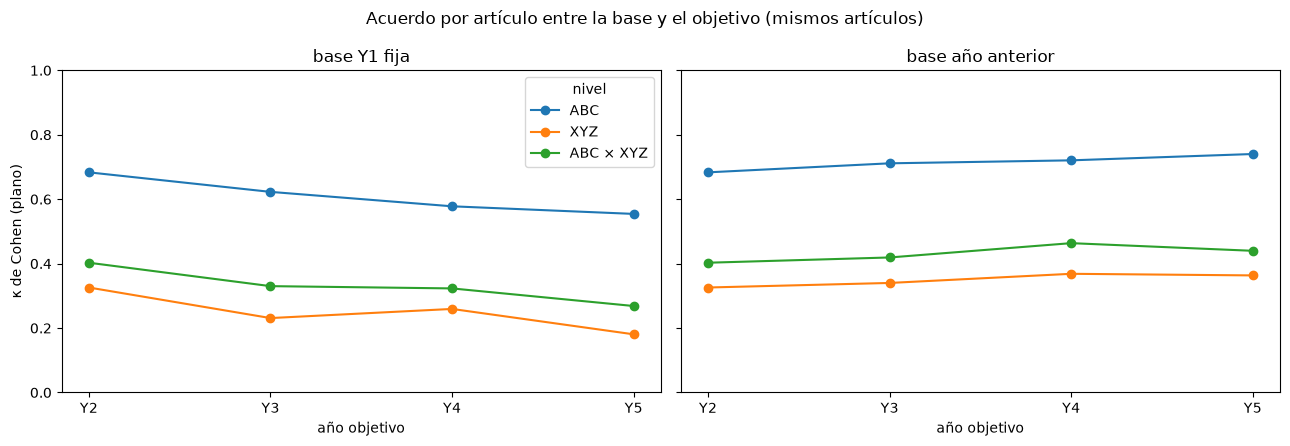

In [48]:
# Mismos artículos en todas las comparaciones: los activos todos los días de Y1 a Y5. Así la
# participación en el gasto se calcula sobre el mismo grupo en la base y en el objetivo, y el
# crecimiento del catálogo no mueve las clases ABC.
panel_mask = ~np.isnan(source_data_artifact["item_units"][:, start_d - 1 : end_d]).any(axis=1)
panel_ids = set(item_ids[panel_mask])
year_mats_panel = year_mats[year_mats["item_id"].isin(panel_ids)]
print(f"artículos activos los cinco años: {len(panel_ids):,} de {len(item_ids):,}")

# Dos bases sin promedios: Y1 fija (cambio acumulado) y año anterior (velocidad del cambio).
names = list(years)
schemes_6b = {
    "Y1 fija": {t: [names[0]] for t in names[1:]},
    "año anterior": {t: [names[i]] for i, t in enumerate(names[1:])},
}
inter_6b = {
    s: {t: base_target_classes(year_mats_panel, years, base, t, source_data_artifact, ABC_RULE,
                               None, CV_CUT_KW)
        for t, base in pm.items()}
    for s, pm in schemes_6b.items()
}
inter_fixed = inter_6b["Y1 fija"]

# Cortes de la base en cada comparación.
cut_cols = ["base", "cut_A", "cut_B", "cv_X", "cv_Z", "n_compared"]
cuts_6b = pd.concat({s: pd.DataFrame([r["summary"] for r in res.values()]).set_index("target")[cut_cols]
                     for s, res in inter_6b.items()}, axis=1)
fmt = {"cut_A": "{:.2f}", "cut_B": "{:.2f}", "cv_X": "{:.1f}", "cv_Z": "{:.1f}", "n_compared": "{:,}"}
display(cuts_6b.style.format({(s, c): f for s in inter_6b for c, f in fmt.items()})
        .set_caption("Cortes de la base por año objetivo (mismos artículos)"))

# κ, Stuart–Maxwell y tamaño del cambio por base, nivel y año objetivo.
LEVELS_6B = {"abc": "ABC", "xyz": "XYZ", "cell": "ABC × XYZ"}
stats_6b = pd.DataFrame([
    {"base": s, "nivel": name, "objetivo": t, **transition_stats(r["items"], level)}
    for s, res in inter_6b.items() for level, name in LEVELS_6B.items() for t, r in res.items()
]).set_index(["base", "nivel", "objetivo"])
show = ["n", "kappa", "stuart_maxwell", "sm_df", "sm_pvalue", "max_shift_pp", "max_shift_class", "spearman"]
display(stats_6b[show].style.format({"n": "{:,}", "kappa": "{:.3f}", "stuart_maxwell": "{:.1f}", "sm_df": "{:d}",
                                     "sm_pvalue": "{:.4f}", "max_shift_pp": "{:.1f}", "spearman": "{:.3f}"},
                                    na_rep="–")
        .set_caption("Cambio de clase por base, nivel y año objetivo (mismos artículos)"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, s in zip(axes, inter_6b):
    for name in LEVELS_6B.values():
        sub = stats_6b.query("base == @s and nivel == @name").droplevel(["base", "nivel"])
        ax.plot(sub.index, sub["kappa"], marker="o", label=name)
    ax.set(title=f"base {s}", xlabel="año objetivo", ylim=(0, 1))
axes[0].set_ylabel("κ de Cohen (plano)")
axes[0].legend(title="nivel")
fig.suptitle("Acuerdo por artículo entre la base y el objetivo (mismos artículos)")
fig.tight_layout()
plt.show()


,Y1,Y2,Y3,Y4,Y5
cell,,,,,
AX,7.4,8.3,7.1,8.9,8.8
AY,11.3,11.9,11.2,9.3,9.2
AZ,3.6,2.3,3.0,3.2,2.7
BX,7.9,8.1,7.8,7.3,10.4
BY,13.1,11.2,11.6,11.3,10.0
BZ,3.9,3.2,4.7,5.1,3.8
CX,8.4,9.4,6.9,10.3,14.1
CY,28.2,28.1,29.0,28.6,29.2
CZ,16.1,17.5,18.6,16.1,11.7


,Y1,Y2,Y3,Y4,Y5
cell,,,,,
A,22.4,22.4,21.3,21.3,20.8
B,24.9,22.5,24.1,23.7,24.2
C,52.7,55.0,54.6,55.0,55.0


,Y1,Y2,Y3,Y4,Y5
cell,,,,,
X,23.7,25.8,21.8,26.4,33.3
Y,52.7,51.2,51.9,49.2,48.4
Z,23.6,23.0,26.3,24.4,18.3


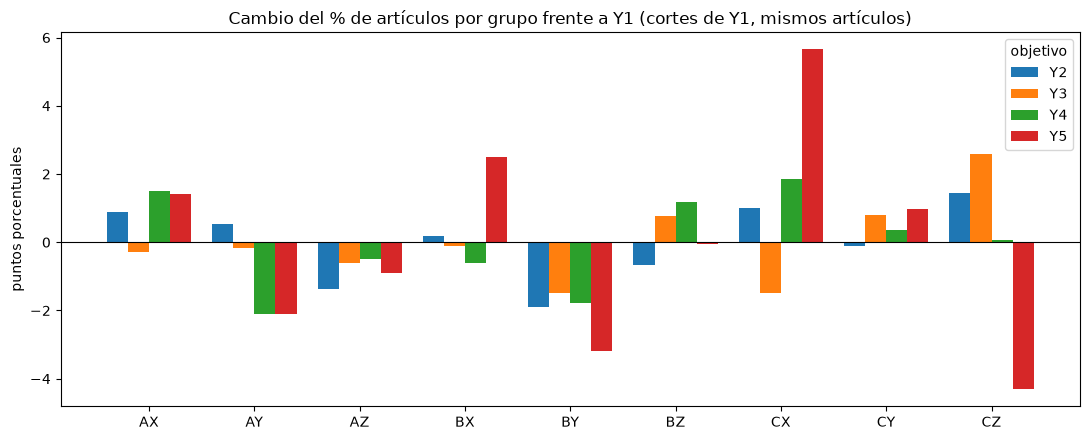

In [49]:
# Composición con la regla de Y1: % de artículos por grupo, por clase ABC y por clase XYZ.
props_fixed = pd.concat({t: r["proportions"].set_index("cell") for t, r in inter_fixed.items()}, axis=1)
composition_6b = pd.DataFrame({names[0]: props_fixed[(names[1], "base_pct")],
                               **{t: props_fixed[(t, "target_pct")] for t in names[1:]}})
display(composition_6b.style.format("{:.1f}").set_caption("% de artículos por grupo con los cortes de Y1"),
        composition_6b.groupby(composition_6b.index.str[0]).sum().style.format("{:.1f}")
        .set_caption("% de artículos por clase ABC"),
        composition_6b.groupby(composition_6b.index.str[1]).sum().style.format("{:.1f}")
        .set_caption("% de artículos por clase XYZ"))

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(CELL_LABELS))
width = 0.8 / len(names[1:])
for k, t in enumerate(names[1:]):
    ax.bar(x + k * width, composition_6b.loc[CELL_LABELS, t] - composition_6b.loc[CELL_LABELS, names[0]],
           width, label=t)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x + width * (len(names) - 2) / 2, CELL_LABELS)
ax.set(title="Cambio del % de artículos por grupo frente a Y1 (cortes de Y1, mismos artículos)",
       ylabel="puntos porcentuales")
ax.legend(title="objetivo")
fig.tight_layout()
plt.show()

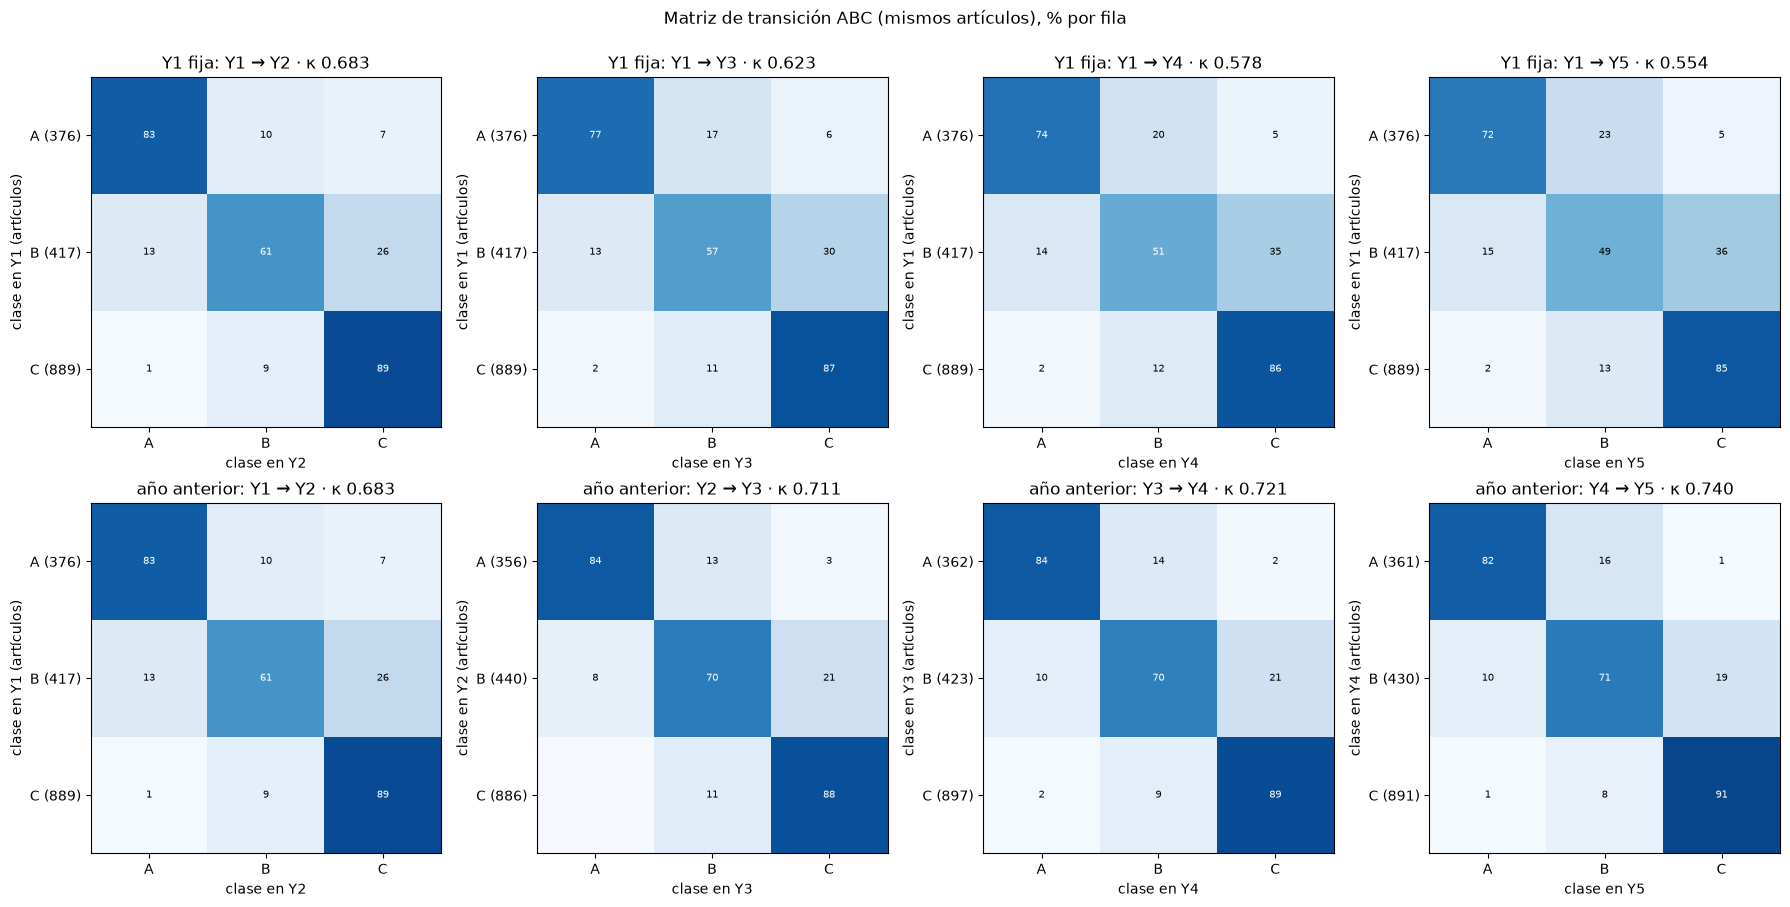

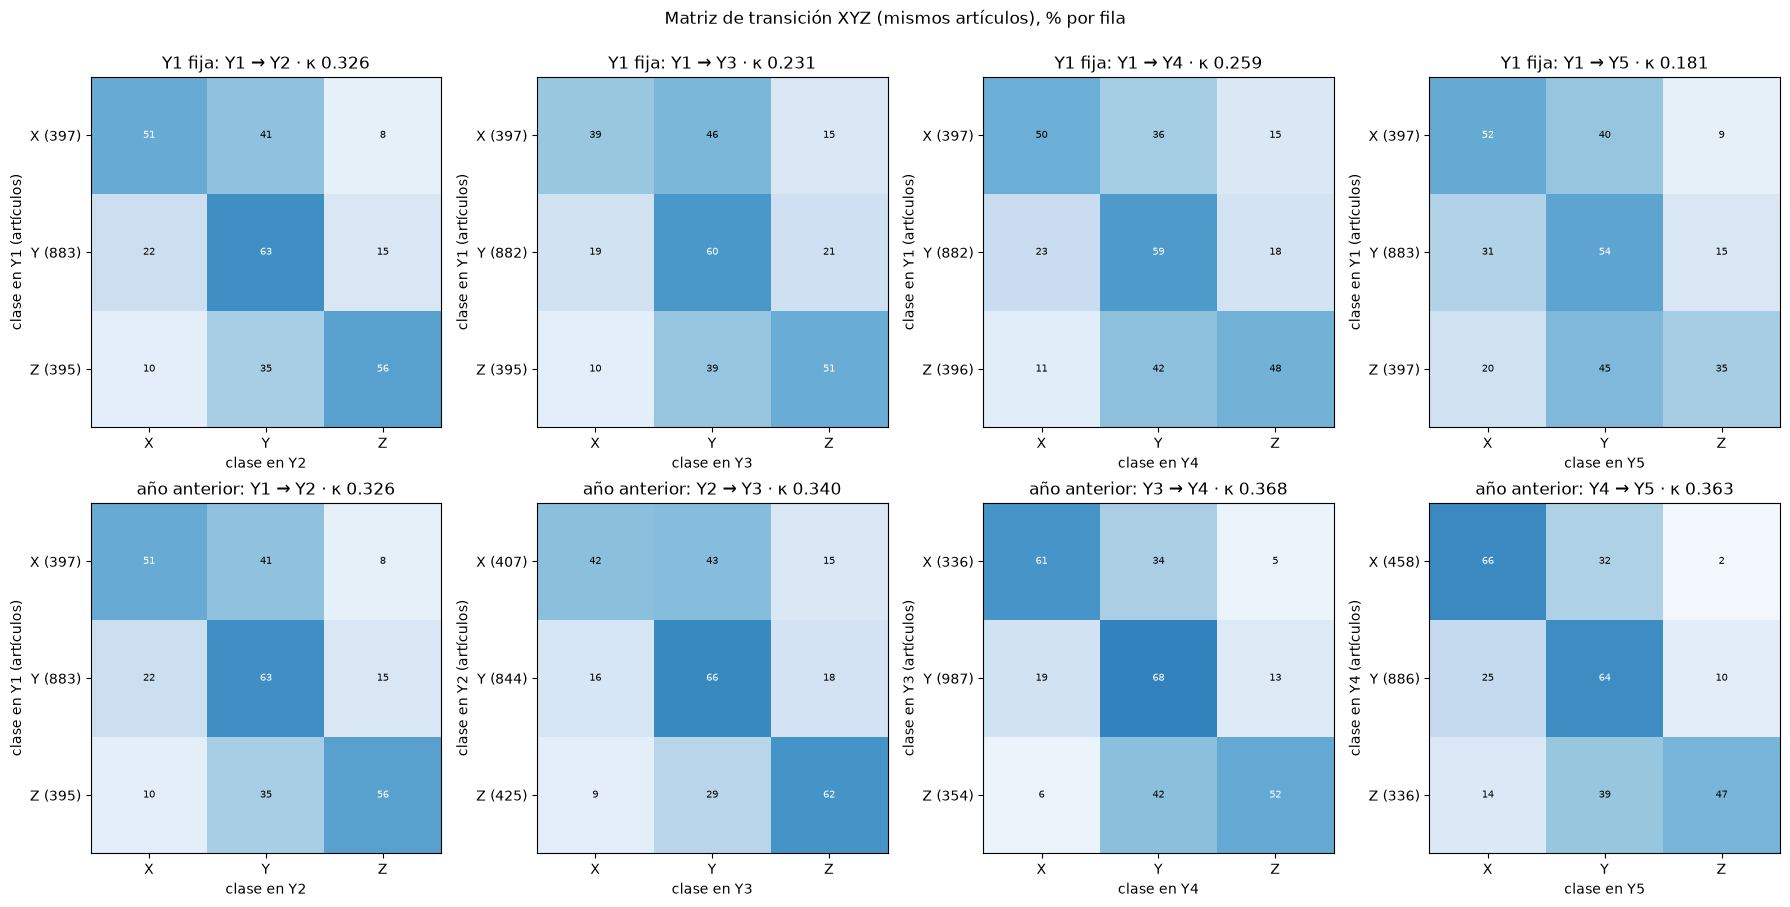

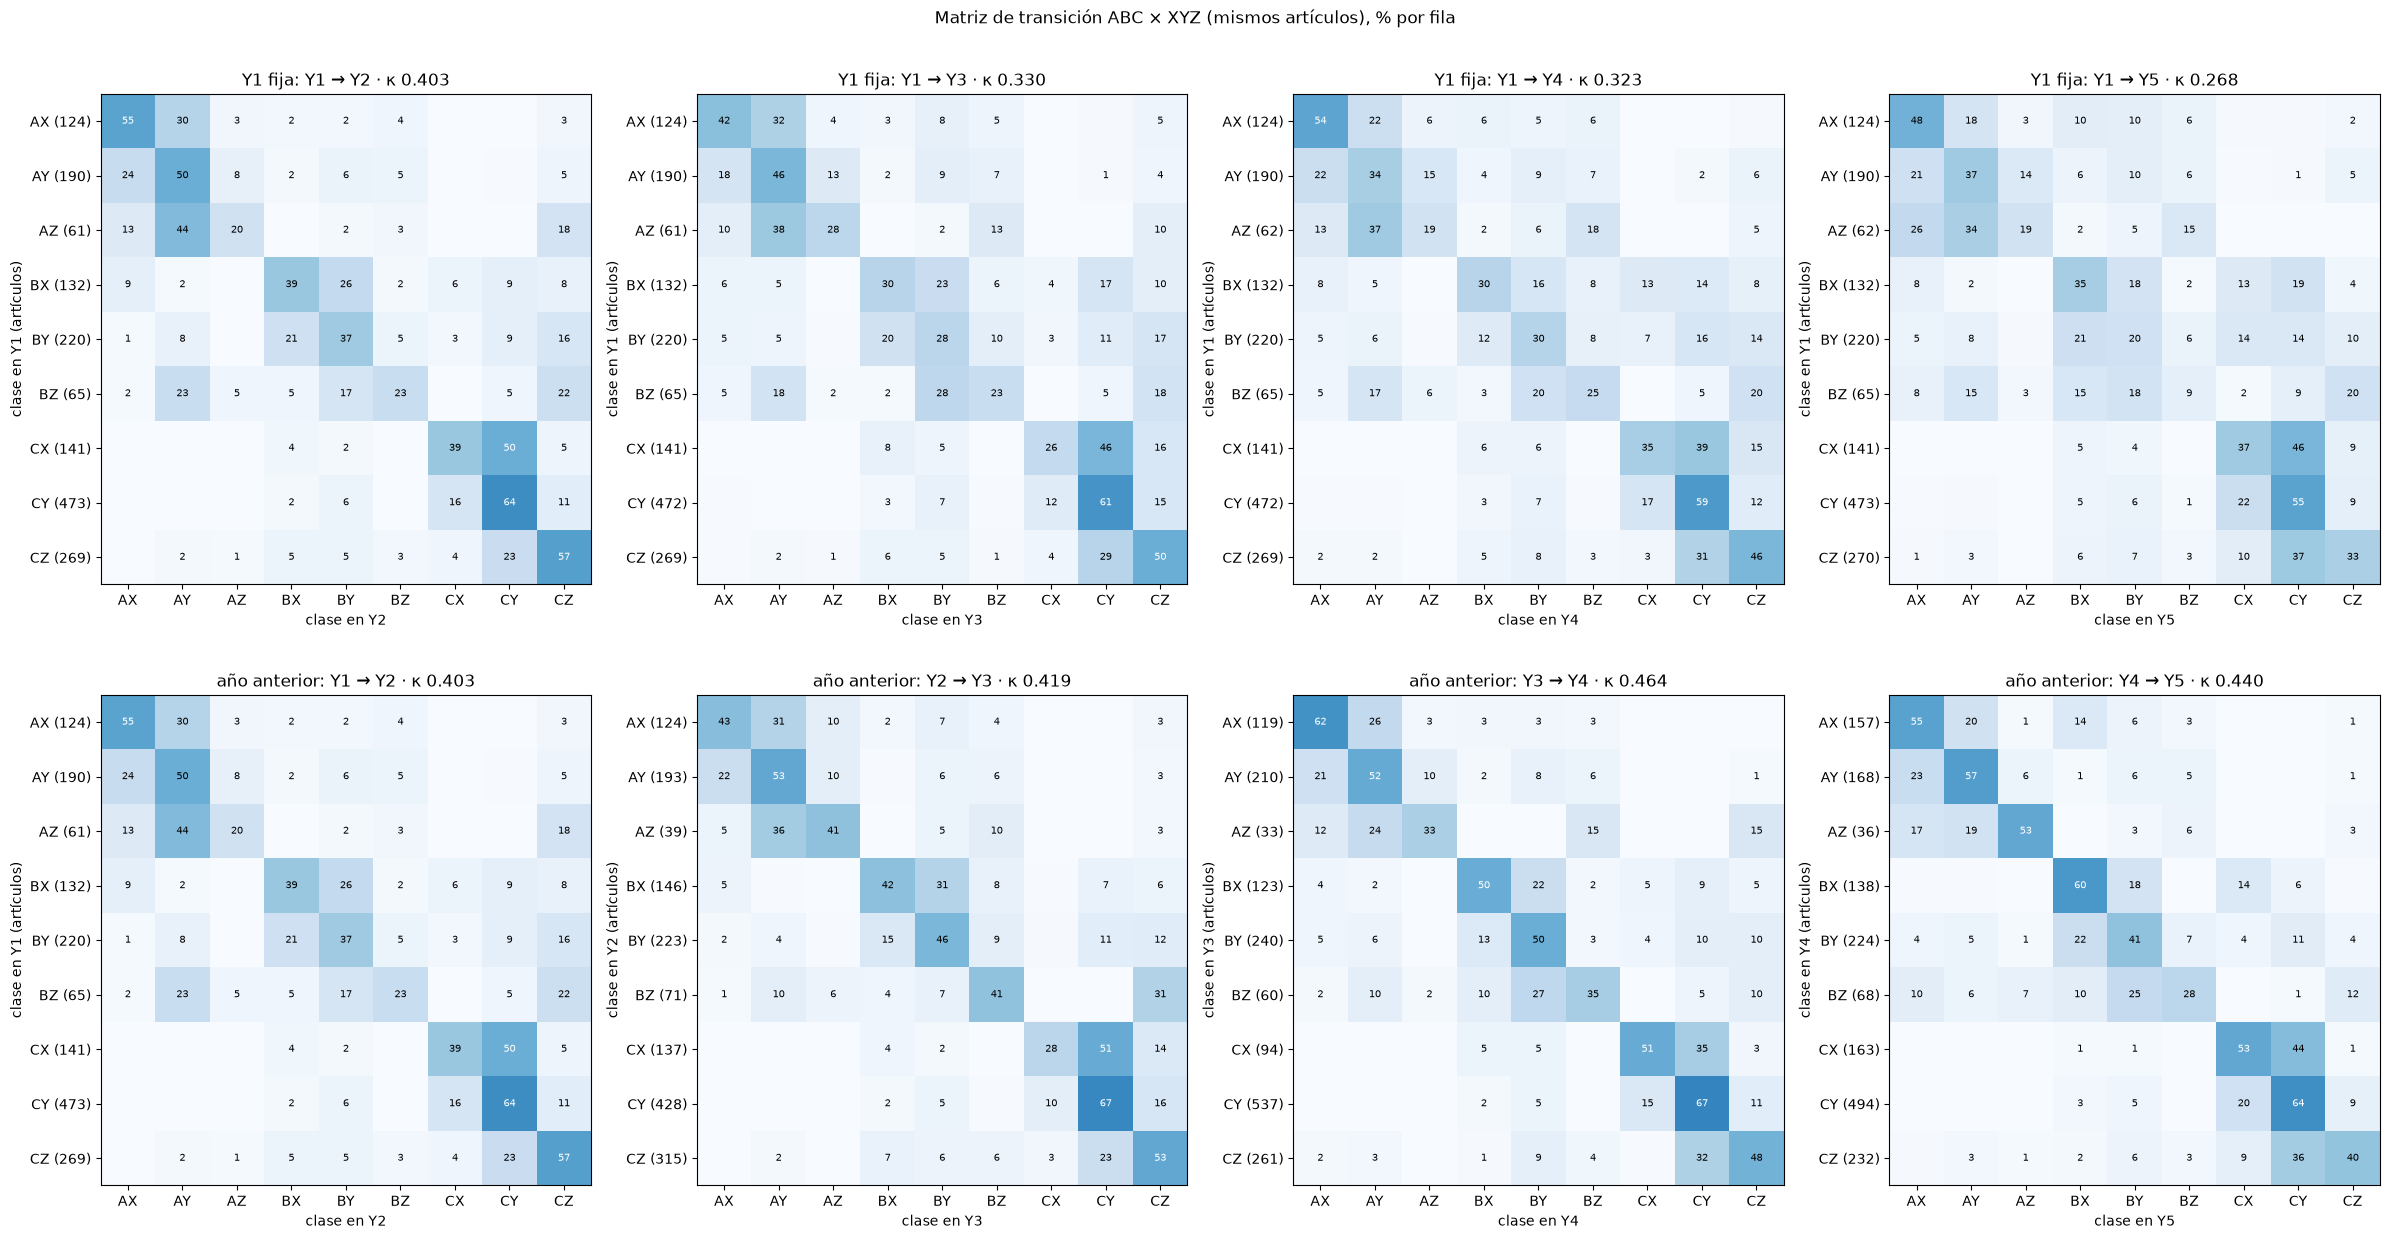

In [50]:
# Matrices de transición en los tres niveles. Fila de arriba: base Y1 fija (cambio acumulado);
# fila de abajo: base año anterior (año a año).
LEVEL_COLS = {"ABC": ("ref_abc", "tgt_abc", ABC_LABELS), "XYZ": ("ref_xyz", "tgt_xyz", XYZ_LABELS),
              "ABC × XYZ": ("ref_cell", "tgt_cell", CELL_LABELS)}


def transition_counts(r, name):
    """Conteos base × objetivo de los artículos con clase en los dos lados."""
    ref, tgt, labels = LEVEL_COLS[name]
    it = r["items"]
    both = it[(it["status"] == "both") & it[ref].notna() & it[tgt].notna()]
    return pd.crosstab(both[ref], both[tgt]).reindex(index=labels, columns=labels, fill_value=0)


for name in LEVEL_COLS:
    big = name == "ABC × XYZ"
    fig, axes = plt.subplots(2, len(names) - 1, figsize=(24, 12.5) if big else (18, 9))
    for row, (s, res) in zip(axes, inter_6b.items()):
        for ax, (t, r) in zip(row, res.items()):
            counts = transition_counts(r, name)
            st = stats_6b.loc[(s, name, t)]
            assert counts.to_numpy().sum() == st["n"], (s, name, t)
            base = r["summary"]["base"]
            heatmap_pct(ax, counts, f"{s}: {base} → {t} · κ {st['kappa']:.3f}", f"clase en {t}",
                        f"clase en {base} (artículos)")
    fig.suptitle(f"Matriz de transición {name} (mismos artículos), % por fila", y=1.0)
    fig.tight_layout()
    plt.show()

# Mantiene / mejora / empeora en los tres niveles; mixto solo existe en ABC × XYZ.
moves = stats_6b[["n", "keep_pct", "up_pct", "down_pct", "mixed_pct"]].rename(
    columns={"keep_pct": "mantiene", "up_pct": "mejora", "down_pct": "empeora", "mixed_pct": "mixto"})
display(moves.style.format({"n": "{:,}", **{c: "{:.1f}" for c in ["mantiene", "mejora", "empeora", "mixto"]}},
                           na_rep="–")
        .set_caption("% de artículos que mantienen, mejoran o empeoran su clase frente a la base"))


In [51]:
# CV anual de los mismos artículos por año: explica el cambio de XYZ en Y5.
cv_by_year = year_mats_panel.dropna(subset=["cv"]).groupby("set_id")["cv"]
cv_quantiles = cv_by_year.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).unstack()
cv_quantiles.columns = [f"p{round(q * 100)}" for q in cv_quantiles.columns]
cv_quantiles.insert(0, "n_items", cv_by_year.size())
display(cv_quantiles.style.format({"n_items": "{:,}", **{c: "{:.1f}" for c in cv_quantiles.columns[1:]}})
        .set_caption("CV anual (%) por año, mismos artículos: cuantiles"))

,n_items,p10,p25,p50,p75,p90
set_id,,,,,,
Y1,"1,677",11.2,14.7,23.0,48.0,72.6
Y2,"1,678",10.6,14.3,22.0,46.5,81.1
Y3,"1,679",11.1,15.4,25.9,51.4,75.6
Y4,"1,680",10.0,14.1,23.2,48.6,72.5
Y5,"1,682",9.2,12.6,19.1,36.2,66.2


### Conclusión de la 8.2

- **ABC es estable en composición y bastante estable por artículo.** El % de artículos por clase casi no se mueve: el mayor cambio es 2,4 pp frente a Y1 y ≤ 1,1 pp año a año desde Y3 (Stuart–Maxwell p ≥ 0,38). Por artículo, κ 0,68–0,74 año a año: 81–84 % mantiene la clase y el resto se reparte parejo entre mejora y empeora. Frente a Y1 el κ baja de 0,68 a 0,55 (73 % mantiene en Y5): deriva lenta que se acumula.
- **XYZ es inestable en los dos sentidos.** Por artículo, κ 0,33–0,37 año a año (59–63 % mantiene la clase) y de 0,33 a 0,18 frente a Y1; el CV de un año predice poco el del siguiente (Spearman 0,47–0,62). En composición, X crece cada año (+3,6, +4,7 y +6,7 pp de Y3 a Y5; Stuart–Maxwell p ≤ 0,002) y frente a Y1 llega a +9,6 pp en Y5, en línea con el CV anual a la baja (tabla de cuantiles).
- **El cambio de grupo ABC × XYZ viene sobre todo de XYZ.** El κ conjunto (0,40–0,46 año a año; 0,40 → 0,27 frente a Y1) queda entre el de ABC y el de XYZ. Año a año el 50–56 % mantiene el grupo, 22–26 % mejora, 19–27 % empeora y solo 0,7–1,5 % es mixto (sube en una dimensión y baja en la otra). Frente a Y1 la permanencia baja de 50 % a 38 % en Y5 y las mejoras pasan de 26 % a 33 %, por el corrimiento de XYZ hacia X. El mayor cambio de composición es 5,7 pp (CX, Y5 frente a Y1).
- **Significativo no es lo mismo que grande.** Con n ≈ 1.680, Stuart–Maxwell marca como significativos cambios de ~2 pp (ABC frente a Y1, p 0,03–0,08). Los cambios de composición de tamaño relevante son los de XYZ: ≥ 3,5 pp y en aumento.
- **Frente a la versión con PSI:** el PSI decía "estable" en todos los años (≤ 0,069). Para ABC la lectura se mantiene. Para XYZ cambia: el reparto se corre hacia X un poco cada año, y en Y5 el corrimiento es claro.
- **Proporciones estables no implican series estacionarias.** Estas medidas hablan del reparto de artículos entre clases, no de la media o la varianza de cada serie. La estacionariedad se prueba serie por serie en la etapa de pronóstico.
- **Nota para train:** FR-016 usa el promedio de los años previos como referencia de estabilidad, así que el sesgo del promedio (8.1) puede aparecer en la etapa 4. ABC es la clase confiable para la estabilidad; la XYZ anual rota mucho (κ ~0,35), así que una `stability_rule` que exija la misma XYZ todos los años dejaría pocos artículos. Queda anotado, sin cambiar la spec.


## 9 · Análisis intraanual

**Pregunta:** ¿la clase ABC anual sirve todo el año, o la clase cambia entre periodos (trimestres `quarter` o cuatrimestres `four_month`) de forma que convenga segmentar?

**Por qué no se compara el periodo con su propio año** (planteamiento anterior):

1. El periodo es parte del año (~25 % del gasto de un trimestre), así que el acuerdo sale inflado por construcción.
2. Las ventanas no tienen el mismo largo (13 frente a 52 semanas): el periodo corto es más ruidoso y su ruido se confunde con estacionalidad.
3. No hay línea base: no se sabe cuánta movilidad esperar si no hubiera estacionalidad, ni se separa un cambio que se repite cada año de uno aleatorio.

**Método:** solo ABC, siempre entre ventanas del mismo largo y con los **mismos artículos de la 8.2** (activos todos los días de Y1 a Y5). La regla de la sección 7 (`ABC_RULE`) se elige en la base y sus fronteras de participación clasifican el objetivo (`base_target_classes`). Tres comparaciones:

| Comparación | Base → objetivo | Qué mide |
|---|---|---|
| `noise` | semanas impares → pares del mismo periodo | Ruido: misma época, sin estacionalidad entre las dos mitades |
| `adjacent` | periodo → periodo siguiente (Q4 → Q1 del año siguiente) | Cambio dentro del año |
| `same_last_year` | mismo periodo del año anterior → periodo | Si el patrón se repite |

- **Pregunta 1 (¿cambia más que el ruido?):** `adjacent` frente a `noise`.
- **Pregunta 2 (¿se repite?):** si `same_last_year` se parece más que `adjacent` (Δκ > 0), la clase depende de la época del año y segmentar tiene sentido.

**Medidas** (`transition_stats`): kappa de Cohen (acuerdo descontado el azar; 1 = igual), índice de movilidad de Shorrocks (0 = nadie cambia), % que mantiene la clase y correlación de Spearman del gasto. Y5 entra solo como descripción.

**Límite de la línea base:** cada mitad dura ~6,5 semanas, la mitad de un trimestre, así que es más ruidosa que un periodo completo. La línea base es **conservadora**: si `adjacent` queda por debajo del kappa de `noise`, el cambio no es ruido de la ventana.

In [52]:
# Mismos artículos que la 8.2: la participación se calcula sobre el mismo grupo en todas las
# comparaciones y el crecimiento del catálogo no mueve las clases.
names = list(years)
rows = []
for kind in ["quarter", "four_month"]:  # descripción; ya no es parámetro (constitución 2.0.0)
    prefix = SEGMENT_PREFIX[kind]
    bounds = {f"{y}-{prefix}{k}": b for y, (a, e) in years.items()
              for k, b in enumerate(segment_bounds(kind, a, e), start=1)}
    halves = [interleaved_halves(source_data_artifact, sid, a, b, wod) for sid, (a, b) in bounds.items()]
    mats_k = pd.concat([period_matrices(source_data_artifact, years, seg, kind, wod), *halves],
                       ignore_index=True)
    mats_k = mats_k[mats_k["item_id"].isin(panel_ids)]
    # Las mitades exigen actividad en todo el periodo.
    ranges_k = {**bounds, **{f"{sid}-{h}": b for sid, b in bounds.items() for h in ("odd", "even")}}
    noise = pd.DataFrame({"comparison": "noise", "base_id": [f"{s}-odd" for s in bounds],
                          "target_id": [f"{s}-even" for s in bounds]})
    n_periods = len(segment_bounds(kind, *years[names[0]]))
    pairs = pd.concat([noise, period_pairs(names, n_periods, prefix)], ignore_index=True)
    for cmp_, base_id, target_id in pairs.itertuples(index=False):
        r = base_target_classes(mats_k, ranges_k, [base_id], target_id, source_data_artifact, ABC_RULE,
                                EDA_PSI)
        year, period = target_id.split("-")[:2]
        rows.append({"kind": kind, "comparison": cmp_, "base_id": base_id, "target_id": target_id,
                     "year": year, "period": period, **transition_stats(r["items"])})
intra_stats = pd.DataFrame(rows)
print(f"comparaciones: {len(intra_stats)} · artículos por comparación: "
      f"{intra_stats['n'].min():,}–{intra_stats['n'].max():,} (panel: {len(panel_ids):,})")

comparaciones: 96 · artículos por comparación: 1,682–1,682 (panel: 1,682)


### 9.1 · ¿Cambia la clase dentro del año más allá del ruido?

Cada celda es una comparación, ubicada en el año y periodo del objetivo: kappa de las mitades del mismo periodo (`noise`) y kappa frente al periodo anterior (`adjacent`; la celda Y1 del primer periodo queda vacía porque no hay periodo anterior). Si `adjacent` es claramente menor que `noise`, la clase cambia entre periodos más de lo que explica el ruido.

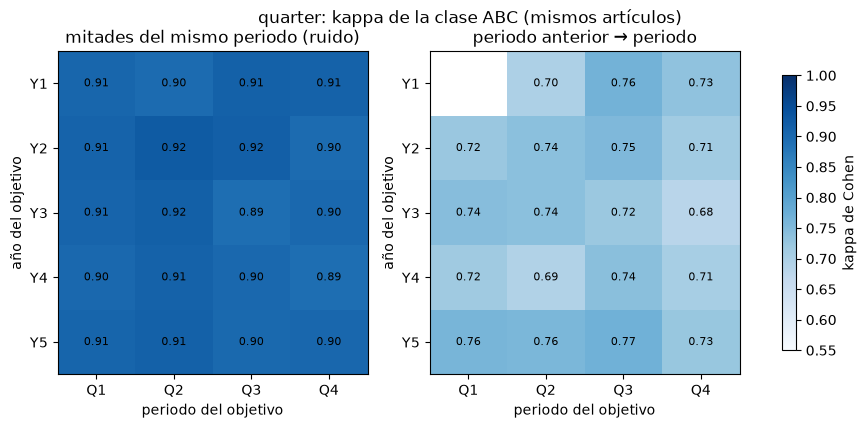

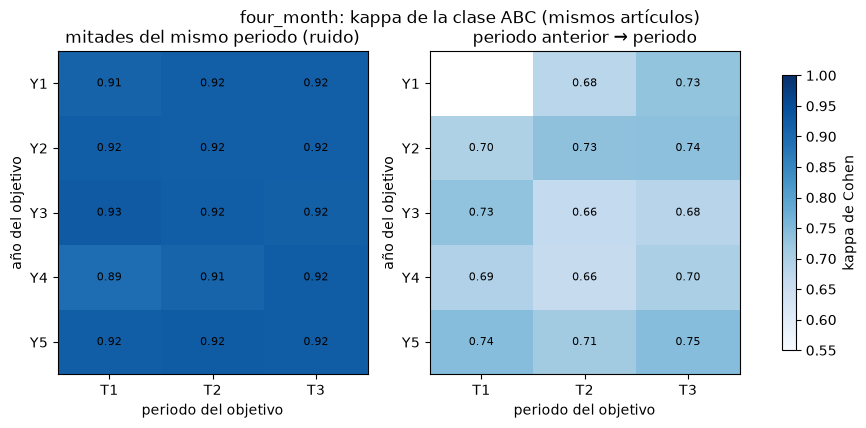

In [53]:
CMP_LABELS = {"noise": "mitades del mismo periodo (ruido)", "adjacent": "periodo anterior → periodo",
              "same_last_year": "mismo periodo del año anterior → periodo"}


def grid(df, value):
    # Año × periodo del objetivo.
    return df.pivot(index="year", columns="period", values=value).reindex(names)


def grid_heatmap(ax, mat, title, cmap, vmin, vmax, fmt="{:.2f}"):
    # Heatmap año × periodo con el valor escrito en cada celda.
    im = ax.imshow(mat.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(mat.shape[1]), mat.columns)
    ax.set_yticks(range(mat.shape[0]), mat.index)
    ax.set(title=title, xlabel="periodo del objetivo", ylabel="año del objetivo")
    return im


kappa_min = np.floor(intra_stats["kappa"].min() * 20) / 20
for kind, df in intra_stats.groupby("kind", sort=False):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, cmp_ in zip(axes, ("noise", "adjacent")):
        im = grid_heatmap(ax, grid(df[df["comparison"] == cmp_], "kappa"), CMP_LABELS[cmp_],
                          "Blues", kappa_min, 1)
    fig.colorbar(im, ax=axes, shrink=0.85, label="kappa de Cohen")
    fig.suptitle(f"{kind}: kappa de la clase ABC (mismos artículos)")
    plt.show()

metrics = ["n", "kappa", "mobility", "keep_pct", "up_pct", "down_pct", "spearman"]
summary_q1 = intra_stats.groupby(["kind", "comparison"], sort=False)[metrics].median()
display(summary_q1.style.format({"n": "{:,.0f}", "kappa": "{:.3f}", "mobility": "{:.3f}",
                                 "keep_pct": "{:.1f}", "up_pct": "{:.1f}", "down_pct": "{:.1f}",
                                 "spearman": "{:.3f}"})
        .set_caption("Mediana de las medidas por candidato y comparación"))

### 9.2 · ¿El cambio se repite cada año?

Δκ = κ(mismo periodo del año anterior → periodo) − κ(periodo anterior → periodo), con el mismo objetivo en las dos. Δκ > 0 (rojo) quiere decir que el periodo se parece más al mismo periodo del año pasado que a su vecino: la clase depende de la época del año. Δκ ≈ 0 o < 0 (azul) quiere decir que el cambio no se repite, o que pesa más la deriva entre años que la época.

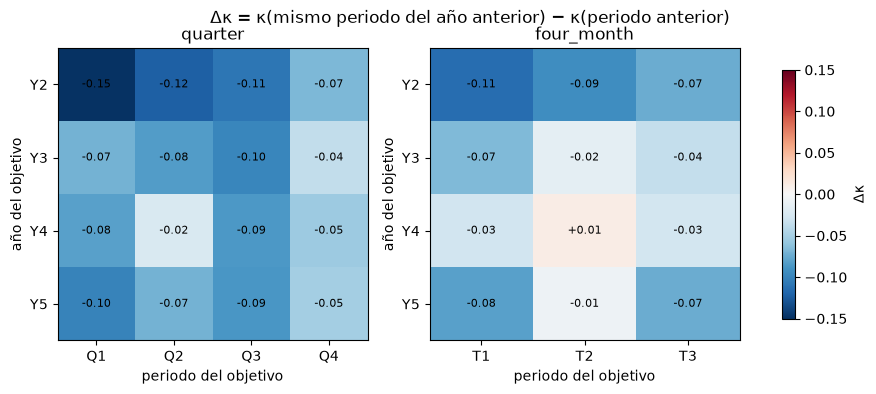

,kappa_same_last_year,kappa_adjacent,delta_mean,delta_min,delta_max,pct_delta_pos
kind,,,,,,
four_month,0.658,0.709,-0.051,-0.114,0.012,8
quarter,0.649,0.730,-0.081,-0.149,-0.023,0


In [54]:
wide = intra_stats[intra_stats["comparison"] != "noise"].pivot_table(
    index=["kind", "year", "period"], columns="comparison", values="kappa").dropna()
wide["delta"] = wide["same_last_year"] - wide["adjacent"]
wide = wide.reset_index()

lim = max(0.05, np.ceil(wide["delta"].abs().max() * 20) / 20)
kinds = list(dict.fromkeys(intra_stats["kind"]))
fig, axes = plt.subplots(1, len(kinds), figsize=(5.5 * len(kinds), 3.8))
for ax, kind in zip(np.atleast_1d(axes), kinds):
    mat = wide[wide["kind"] == kind].pivot(index="year", columns="period", values="delta")
    im = grid_heatmap(ax, mat.reindex(names[1:]), kind, "RdBu_r", -lim, lim, fmt="{:+.2f}")
fig.colorbar(im, ax=axes, shrink=0.85, label="Δκ")
fig.suptitle("Δκ = κ(mismo periodo del año anterior) − κ(periodo anterior)")
plt.show()

summary_q2 = wide.groupby("kind", sort=False).agg(
    kappa_same_last_year=("same_last_year", "mean"), kappa_adjacent=("adjacent", "mean"),
    delta_mean=("delta", "mean"), delta_min=("delta", "min"), delta_max=("delta", "max"),
    pct_delta_pos=("delta", lambda d: (d > 0).mean() * 100))
display(summary_q2.style.format("{:.3f}", subset=summary_q2.columns[:-1])
        .format("{:.0f}", subset=["pct_delta_pos"])
        .set_caption("Kappa medio por comparación y Δκ por candidato (Y2–Y5)"))

### Conclusión de la 9.1 y la 9.2

- **La clase cambia entre periodos más de lo que explica el ruido.** Las mitades del mismo periodo coinciden casi siempre (κ mediano 0,91 en trimestres y 0,92 en cuatrimestres; 94–95 % mantiene la clase), aunque cada mitad dura la mitad que un periodo. Entre periodos consecutivos el acuerdo baja a κ 0,73 (trimestres) y 0,71 (cuatrimestres): 16–18 % de los artículos cambia de clase, repartido por igual entre subir y bajar (~8 % cada uno). La caída es pareja en todos los años y periodos; ningún trimestre destaca.
- **El cambio no se repite cada año.** El mismo periodo del año anterior se parece **menos** que el periodo vecino: Δκ < 0 en las 16 celdas de trimestres (media −0,08) y en 11 de 12 de cuatrimestres (media −0,05; la única positiva, Y4-T2, es +0,01). El acuerdo cae con la distancia en el tiempo (13 semanas: κ 0,73; 52 semanas: κ 0,65): es **deriva** del peso de cada artículo, no estacionalidad de la clase.
- **Lectura conjunta con la 9.3:** la demanda sí tiene un patrón mensual (pico de junio a septiembre y bajón de noviembre a enero; Friedman significativo en 13 de 15 segmentos). La amplitud cambia entre grupos (AZ va de 0,85 a 1,22; CX de 0,93 a 1,06), así que la participación de un artículo puede moverse dentro del año, pero según la 9.2 ese movimiento no se repite cada año. No alcanza para que la clase ABC dependa de la época del año.
- **Implicación:** no hay evidencia para segmentar la clase ABC por trimestre o cuatrimestre; lo que importa es la deriva entre años, coherente con la 8.2 (~50 % cambia de grupo por año). Entre los dos candidatos, el cuatrimestre tiene algo menos de deriva relativa (Δκ más cercano a 0), pero la diferencia es pequeña.
- **Límite:** `same_last_year` está más lejos en el tiempo que `adjacent`, así que la deriva lo penaliza. Un efecto estacional tendría que superar esa deriva, y no lo hace en ninguna celda de trimestres.
- **Nota para la etapa 4:** `choose_segment_period` (criterio `max_mean_abc_agreement`) compara cada periodo con su propio año, el método descartado aquí por su acuerdo inflado. Queda anotado, sin cambiar la spec ni el código.


### 9.3 · Índice estacional clásico

Método clásico de razón a media móvil, sobre la serie **agregada** de cada segmento (ABC, XYZ y ABC × XYZ):

1. Solo artículos con dato todos los días de Y1–Y5 (los mismos de la 8.2). Los lanzamientos se concentran en enero–abril: su salto de nivel y su arranque se confundirían con estacionalidad.
2. Serie mensual: unidades diarias promedio del agregado en cada mes calendario **completo** (jun-2011 a abr-2016). La media diaria evita que los meses de 28–31 días parezcan estacionalidad.
3. Media móvil centrada 2×12 (la tendencia). Se pierden 6 meses en cada extremo.
4. Ratio = serie / media móvil.
5. Mes típico = **promedio** de los ratios del mismo mes entre años.
6. Normalización: los 12 índices suman 12 (media 1).

**Límite:** describe a los artículos maduros. Las columnas `n_items` y `% gasto cubierto` dicen cuánto del segmento entra; donde la cobertura es baja (C y grupos con muchos lanzamientos), el índice se apoya en menos muestra.

In [55]:
dates = pd.to_datetime(calendar["date"]).to_numpy()
by_item = groups.set_index("item_id")
levels = {
    "ABC": (by_item["abc_class"], ["A", "B", "C"]),
    "XYZ": (by_item["xyz_class"], ["X", "Y", "Z"]),
    "ABC × XYZ": (by_item["group"], group_order),
}
months = list(range(1, 13))

classical = {}
for name, (classes, order) in levels.items():
    res = classical_seasonal_index(source_data_artifact, classes, dates, start_d, end_d)
    assert np.allclose(res["index"].mean(axis=1), 1), "cada fila debe promediar 1"
    used = res["items"]
    coverage = by_item["spend"].reindex(used.index).groupby(used).sum() / by_item["spend"].groupby(classes).sum() * 100
    table = res["index"].reindex([c for c in order if c in res["index"].index])
    table["n_items"] = res["n_items"]
    table["% gasto cubierto"] = coverage
    classical[name] = res
    display(table.style.format("{:.2f}", subset=months).format("{:,}", subset=["n_items"])
            .format("{:.1f}", subset=["% gasto cubierto"])
            .background_gradient(cmap="RdBu_r", vmin=0.6, vmax=1.4, axis=None, subset=months)
            .set_caption(f"Índice estacional clásico por {name} (razón a media móvil 2×12, promedio entre años)"))

ratios = classical["ABC"]["ratios"]
print(f"ratios: {ratios['period'].min()} a {ratios['period'].max()}; por mes:",
      ratios[ratios["class"] == "A"].groupby("month").size().to_dict())

month,1,2,3,4,5,6,7,8,9,10,11,12,n_items,% gasto cubierto
class,,,,,,,,,,,,,,
A,0.93,0.96,0.98,0.97,0.97,1.07,1.08,1.11,1.07,0.97,0.95,0.95,442,72.2
B,0.98,1.05,1.00,0.98,0.98,1.05,1.01,1.04,1.01,0.99,0.96,0.94,774,66.7
C,0.96,1.03,1.02,0.99,1.01,1.04,1.02,1.03,1.00,1.02,0.94,0.93,466,42.7


month,1,2,3,4,5,6,7,8,9,10,11,12,n_items,% gasto cubierto
class,,,,,,,,,,,,,,
X,0.93,1.01,0.98,0.96,0.98,1.03,1.04,1.08,1.01,1.00,0.99,0.99,441,68.1
Y,0.97,1.00,1.00,0.99,0.97,1.05,1.05,1.05,1.05,0.99,0.95,0.92,837,68.1
Z,0.95,0.96,0.96,0.95,0.99,1.12,1.10,1.15,1.09,0.92,0.89,0.92,404,65.7


month,1,2,3,4,5,6,7,8,9,10,11,12,n_items,% gasto cubierto
class,,,,,,,,,,,,,,
AX,0.89,1.00,0.98,0.95,0.98,1.03,1.05,1.09,1.02,1.00,1.00,1.01,138,74.0
AY,0.96,0.96,1.00,0.99,0.96,1.05,1.07,1.08,1.09,1.00,0.94,0.91,217,73.6
AZ,0.94,0.91,0.95,0.93,0.98,1.18,1.15,1.22,1.11,0.85,0.85,0.94,87,65.7
BX,0.99,1.03,0.98,0.98,0.97,1.03,1.02,1.06,1.01,1.00,0.98,0.95,213,64.0
BY,0.98,1.06,1.02,0.98,0.98,1.06,1.01,1.02,0.99,0.98,0.96,0.94,389,65.9
BZ,0.95,1.03,0.97,0.99,1.01,1.06,1.02,1.07,1.08,0.99,0.94,0.90,172,72.4
CX,0.93,1.01,1.01,1.01,1.00,1.03,1.03,1.06,1.01,0.99,0.97,0.95,90,36.4
CY,0.94,1.03,1.03,1.01,1.04,1.05,1.02,1.01,0.98,1.00,0.95,0.95,231,42.0
CZ,1.00,1.07,1.02,0.95,0.98,1.04,1.01,1.05,1.05,1.06,0.88,0.89,145,49.9


ratios: 2011-12 a 2015-10; por mes: {1: 4, 2: 4, 3: 4, 4: 4, 5: 4, 6: 4, 7: 4, 8: 4, 9: 4, 10: 4, 11: 3, 12: 4}


### 9.4 · ¿Los meses difieren entre sí? Prueba de Friedman

Sobre los ratios del paso 4 (sin tendencia). **Bloques** = años calendario con los 12 ratios; **tratamientos** = meses. Dentro de cada año se ordenan los meses (rangos). H0: ese orden es aleatorio, ningún mes tiende a quedar arriba o abajo. Rechazarla es indicio de estacionalidad estable.

- **Kendall W** = χ² / (b·(k − 1)): consistencia del orden de los meses entre años (0 = ninguna, 1 = el mismo orden todos los años).
- **Pocos bloques:** la media móvil se come 6 meses en cada extremo, así que solo 2012–2014 tienen los 12 ratios (b = 3). Con b tan chico la χ² no es fiable; se usa el p-valor por **permutación** (los meses se barajan dentro de cada año).
- **15 pruebas a la vez** (3 ABC + 3 XYZ + 9 ABC × XYZ): p-valor de permutación ajustado por Holm.
- **Límite:** la prueba mira el orden, no el tamaño. Cuánto difieren los meses lo dice el índice.

In [56]:
# Bloques = años calendario con los 12 ratios (2012–2014); tratamientos = meses.
friedman = pd.concat(
    {name: friedman_seasonality(res["ratios"]) for name, res in classical.items()},
    names=["nivel", "class"],
)
friedman["p_holm"] = multipletests(friedman["p_permutation"], method="holm")[1]
display(friedman.style.format({"n_years": "{:d}", "chi2": "{:.1f}", "p_asymptotic": "{:.4f}",
                               "p_permutation": "{:.4f}", "p_holm": "{:.4f}", "kendall_w": "{:.2f}"})
        .set_caption("Friedman: ¿los meses difieren entre sí? (bloques = años, permutaciones dentro del año)"))

### Conclusión de la 9.3 y la 9.4

- **Hay estacionalidad anual en casi todos los segmentos:** pico de junio a septiembre y bajón de noviembre a enero. Friedman la confirma en 13 de 15 segmentos (p de Holm ≤ 0,03; W 0,64–0,85): el orden de los meses se repite de un año a otro.
- **La amplitud cambia entre segmentos.** Es más marcada en Z y sobre todo en AZ (agosto 1,22; octubre y noviembre 0,85). En B y X se mueve en torno a ±5 %.
- **C y CZ no son significativos** (p de Holm 0,064 y 0,093; W 0,57 y 0,50). Son también los de menor cobertura (43 % y 50 % de su gasto), así que no se distingue si no tienen patrón o si falta muestra.
- **Límites:** solo 3 años completos de ratios (2012–2014), y el índice describe a los artículos activos los cinco años.


In [57]:
from datetime import datetime

year = np.array([datetime.strptime(date, "%Y-%m").year for date in res["ratios"]["period"].astype("str").to_numpy()])

res["ratios"]["year"] = year

res["ratios"]

,class,period,month,ratio,year
0,AX,2011-12,12,1.02,2011
1,AX,2012-01,1,0.90,2012
2,AX,2012-02,2,0.98,2012
3,AX,2012-03,3,0.98,2012
4,AX,2012-04,4,0.97,2012
...,...,...,...,...,...
418,CZ,2015-06,6,1.13,2015
419,CZ,2015-07,7,1.08,2015
420,CZ,2015-08,8,1.03,2015
421,CZ,2015-09,9,0.99,2015


In [58]:
pd.pivot(res["ratios"], index=["class", "year"], columns="month", values="ratio").to_clipboard()

In [59]:
raise Exception("Detener")

Exception: Detener